# 17 – Normalverhaltensmodell je HAST: wetterbereinigte Früherkennung

**Zweck:** Statt „defekt ja/nein“ vorherzusagen, lernt dieses Notebook für jede HAST, wie sie sich
**normalerweise** bei einer bestimmten Außentemperatur verhält. Weicht sie über mehrere Tage davon ab,
gibt es einen Alarm. Die Frage:

> **Lässt sich eine Veränderung an einer Station aus den Tageswerten früh und wetterbereinigt erkennen,
> ohne dass wir Fehler-Labels brauchen?**

**Warum dieser Ansatz** (was die bisherigen Notebooks gezeigt haben)

| Befund | Notebook | Folge hier |
|---|---|---|
| Die Labels taugen nicht: `n_actions > 0` ist bei 76–80 % wahr, Freitext-Labels sind zu wenige | 01, 04, 15, ML-Klassifikator | Zielgröße ist ein **Messwert**, kein Label |
| Die Stationen bilden keine klaren Typen (Silhouette unter 0,25) | 01, 04, 06 | jede Station wird **mit sich selbst** verglichen |
| Begehungen verschieben das **Niveau** der Performance, nicht die Form der Kennlinie | 12, 13 | das Modell schaut auf das Niveau (kWh/m³) |
| Vorher/Nachher ohne Wetterbereinigung vermischt Jahreszeit und Wirkung | 03, 08 | die Erwartung hängt von der **Außentemperatur** ab |
| Stundenwerte sind Momentaufnahmen | Check D2, 06 | Tageswerte aus **Zählerständen** (`hast_tage.csv`) |
| Der Kennlinienmonitor findet den Ventilfall, sonst knapp über Zufall | 14, 15 | dieselben Prüfsteine, damit es vergleichbar bleibt |

**Was am Ende herauskommt**
- je Station und Kanal eine Kennlinie „Erwartung in Abhängigkeit von der Außentemperatur“
- je Tag der Abstand zur Erwartung (Residuum) und ein Alarmzähler (CUSUM)
- eine Alarmliste, eine Prüfung gegen die Begehungen und je Station eine **Normkennzahl** für den Vergleich mit der Flotte

**Ehrlich vorweg:** Das ist **Früherkennung**, keine Prognose. Das Modell sagt nicht „in vier Wochen fällt
die Station aus“, sondern „seit ein paar Tagen läuft die Station anders, als sie bei diesem Wetter sonst läuft“.

**Eingaben**

| Datei | Wofür |
|---|---|
| `data/processed/hast_tage.csv` | Tageszeilen je HAST aus [`06`](06_tagesmerkmale_clusteranalyse.ipynb), inklusive Außentemperatur |
| `data/raw/*Ergebnis_Optimierung_FW*.xlsx` | Begehungen: Datum, Kategorie, Freitext |
| `data/raw/Zuordnung.xlsx` | Adresse → Zählernummer für die Begehungen |

**Eigenständig:** keine Abhängigkeit zu `src/`. Was von dort gebraucht wird (Adress-Normierung,
Freitext-Muster), steht als Kopie im Notebook.

**Ablauf**

| Abschnitt | Inhalt |
|---|---|
| 1 | Setup & Parameter |
| 2 | Tageswerte laden, Form des Zusammenhangs prüfen |
| 3 | Begehungen laden |
| 4 | Referenzzeitraum je Station |
| 5 | Das Modell: eine Kennlinie je Station und Kanal |
| 6 | Wie gut ist die Vorhersage? |
| 7 | Abweichung und Alarm: der CUSUM |
| 8 | Der bekannte Fall 68956351 |
| 9 | Lauf über alle Stationen |
| 10 | Sieht das Modell die Begehungen überhaupt? |
| 11 | Treffen die Alarme die Begehungen? |
| 12 | Station gegen Flotte |
| 13 | Ergebnis speichern |
| 14 | Einordnung und Verbesserungsideen |

## Begriffe

| Begriff | Bedeutung |
|---|---|
| **Kanal** | eine Messgröße, die das Modell überwacht. Hier zwei: **Abkühlung** (kWh/m³) und **Wassermenge** (Tagesvolumen) |
| **Referenzzeitraum** | das erste Jahr einer Station. Daraus lernt das Modell, was für diese Station „normal“ ist |
| **Erwartung** | was die Station laut Modell bei der Außentemperatur dieses Tages liefern sollte |
| **Residuum** | gemessen minus erwartet. Positiv heißt: mehr als erwartet |
| **Streuung s** | wie weit die Station an einem typischen Tag der Referenz von ihrer Kennlinie entfernt liegt |
| **z-Wert** | Residuum geteilt durch s (genauer: durch die wegen der Autokorrelation vergrößerte Streuung, Abschnitt 5). z = 2 heißt: doppelt so weit weg wie an einem typischen Tag |
| **CUSUM** | ein Zähler, der Abweichungen über die Tage aufsummiert, kleine Ausreißer aber verzeiht (Abschnitt 7) |
| **Alarm** | der CUSUM überschreitet seine Schwelle: die Station läuft seit einigen Tagen anders als sonst |
| **Kontrollgruppe** | Stationen ohne Begehung im selben Zeitraum. Sie zeigen, wie oft es ohnehin geklingelt hätte |

## 1 · Setup & Parameter

Alle Stellschrauben stehen in dieser einen Zelle. Was sie bedeuten und warum sie diesen Startwert haben,
steht in der Tabelle unter der Zelle.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

TAGE_PATH = ROOT / "data" / "processed" / "hast_tage.csv"
RAW = ROOT / "data" / "raw"
ZUORDNUNG_PATH = RAW / "Zuordnung.xlsx"
AUSGABE = ROOT / "data" / "processed"

# --- Welche Tage gehen ins Modell? -------------------------------------------------
T_HEIZGRENZE = 15.0                          # nur Heiztage: Tagesmittel unter 15 °C (wie NB 06)
IGNORIERTE_MARKIERUNGEN = {"wenig_stunden"}  # NB-06-Markierungen, die hier nicht stoeren

# --- Kanaele: welche Groessen das Modell ueberwacht ---------------------------------
KANAELE = {
    "kwh_pro_m3": "Abkühlung (kWh/m³)",
    "log_volumen": "Wassermenge (Tagesvolumen)",
}

# --- Modell: Form der Kennlinie je Kanal (Abschnitt 5) --------------------------------
FORM_JE_KANAL = {"kwh_pro_m3": "gerade", "log_volumen": "klassen"}
KLASSENBREITE_K = 2.0     # Breite der Temperaturklassen fuer die Klassenkennlinie
MIN_TAGE_JE_KLASSE = 8    # Klassen mit weniger Referenztagen fallen weg, die Nachbarn werden verbunden
AUTOKORRELATION_BERUECKSICHTIGEN = True   # Streuung vergroessern, weil Folgetage sich aehneln
PHI_MAX = 0.8             # Obergrenze der Autokorrelation in dieser Korrektur (Faktor hoechstens 3)

# --- Referenzzeitraum -----------------------------------------------------------------
REF_KALENDERTAGE = 365    # das erste Jahr einer Station ist ihre Referenz
ABSTAND_BEGEHUNG = 14     # die Referenz endet spaetestens so viele Tage vor der ersten Begehung
MIN_REF_TAGE = 60         # mindestens so viele verwendbare Heiztage in der Referenz
MIN_REF_SPANNE_K = 8.0    # Temperaturspanne der Referenztage in Kelvin

# --- Guetetest der Vorhersage ---------------------------------------------------------
PRUEF_TAGE = 120          # Heiztage direkt nach der Referenz, vor jeder Begehung
MIN_PRUEF_TAGE = 20

# --- Alarm (CUSUM) -----------------------------------------------------------------
CUSUM_K = 0.5             # Toleranz je Tag, in Streuungen s der Station
CUSUM_H = 5.0             # Alarmschwelle
CUSUM_MAX = 10.0          # Deckel des Zaehlers

# --- Abgleich mit den Begehungen ------------------------------------------------------
FENSTER_VOR = 7           # ein Alarm darf so viele Tage vor dem Termin liegen
FENSTER_NACH = 60         # ... und so viele Tage danach
MIN_TAGE_IM_FENSTER = 5   # Heiztage im Fenster, damit eine Station ueberhaupt alarmieren kann
KONTROLL_VORLAUF = 60     # Kontrollstation: keine eigene Begehung so lange vor dem Fenster
MIN_KONTROLLEN = 5        # weniger Kontrollstationen -> Fall wird nicht bewertet
WIRKUNG_TAGE = 30         # Heiztage vor bzw. nach der Begehung fuer die Wirkungsschaetzung
MIN_WIRKUNG_TAGE = 10
WIRKUNG_ABSTAND = 7       # Tage direkt um die Begehung bleiben draussen (Einregelphase)
WIRKUNG_MAX_TAGE = 365    # hoechstens so weit vor bzw. nach der Begehung suchen

# --- Flottenvergleich ----------------------------------------------------------------
T_NORM = 5.0              # Normtemperatur in °C
AKTUELL_TAGE = 60         # letzte Heiztage fuer den aktuellen Stand
RHO_C = 1.15              # kWh je m³ und Kelvin (wie NB 06)

# --- Bekannter Fall -----------------------------------------------------------------
BEISPIEL = 68956351                          # Ventil drei Jahre offen (NB 03, 13, 14, 15)
BEISPIEL_DATUM = pd.Timestamp("2024-09-09")  # Begehung mit Stellmotortausch
SEED = 42

# --- Darstellung (Farben aus NB 06) -------------------------------------------------
FARBE_KANAL = {"kwh_pro_m3": "#2a78d6", "log_volumen": "#c74b12"}
FARBE_BEGANGEN, FARBE_KONTROLLE = "#4a3aa7", "#1baf7a"
TINTE, TINTE_LEISE, GITTER, ACHSE, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#f1f0ec"


def stil(ax):
    """Zurueckhaltende Achsen: nur links/unten, feines Gitter (wie NB 06)."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(ACHSE)
    ax.tick_params(colors=TINTE_LEISE, labelsize=9)
    ax.grid(color=GITTER, linewidth=0.6)
    ax.set_axisbelow(True)


def anzeige(kanal, werte):
    """Werte eines Kanals in lesbaren Einheiten: das Volumen aus dem Logarithmus zurueck in m³."""
    werte = np.asarray(werte, dtype=float)
    return np.exp(werte) if kanal == "log_volumen" else werte


def prozent(log_differenz):
    """Differenz zweier Logarithmen als Prozentaenderung, z. B. 0,1 -> +10,5 %."""
    return 100 * (np.exp(log_differenz) - 1)

**Was macht die Zelle?**
- lädt die Pakete und sucht den Projektordner (wie NB 06: nach oben, bis `notebooks/` auftaucht)
- legt alle Schwellen und Fenster an einer Stelle fest. Wer etwas ausprobieren will, ändert nur hier und
  lässt das Notebook neu laufen
- zwei kleine Hilfsfunktionen für die Anzeige: `anzeige()` rechnet das logarithmierte Volumen zurück in m³,
  `prozent()` macht aus einer Differenz von Logarithmen eine Prozentänderung

**Die Stellschrauben und warum sie so gesetzt sind** (alles Startwerte)

| Parameter | Startwert | Warum | Wenn man ihn ändert |
|---|---|---|---|
| `T_HEIZGRENZE` | 15 °C | darüber wird kaum geheizt, die Station macht fast nur Warmwasser; kWh/m³ hängt dann kaum noch am Wetter | höher: mehr Tage, aber Übergangstage mit anderem Verhalten verbiegen die Kennlinie |
| `IGNORIERTE_MARKIERUNGEN` | `wenig_stunden` | Begründung in Abschnitt 2 | leere Menge `set()` = genau die Tage, die NB 06 `nutzbar` nennt |
| `FORM_JE_KANAL` | Abkühlung `gerade`, Wassermenge `klassen` | die Form, die zum Bild in Abschnitt 2 passt (Begründung in Abschnitt 5) | `klassen` für die Abkühlung, falls Bild 1 krumm ist; `gerade` für die Wassermenge erzeugt Scheinalarme in Kälteperioden |
| `KLASSENBREITE_K` | 2 K | schmal genug, um eine Krümmung abzubilden, breit genug für rund 20–30 Referenztage je Klasse | schmaler: genauer, aber jede Stützstelle wackliger |
| `MIN_TAGE_JE_KLASSE` | 8 | ein Median aus weniger Tagen ist zu unsicher | |
| `AUTOKORRELATION_BERUECKSICHTIGEN` | `True` | aufeinanderfolgende Tage ähneln sich, ohne Korrektur gibt es viel mehr Fehlalarme (Abschnitt 5) | `False`: empfindlicher, aber deutlich mehr Fehlalarme |
| `PHI_MAX` | 0,8 | begrenzt die Korrektur auf höchstens das Dreifache der Streuung, falls eine Station eine extreme Autokorrelation hat | |
| `REF_KALENDERTAGE` | 365 | ein ganzes Jahr enthält kalte und milde Heiztage, die Kennlinie wird über den ganzen Temperaturbereich gelernt | kürzer: mehr Zeit zum Überwachen, aber die Kennlinie wird an wenigen Temperaturen gelernt und später verlängert |
| `ABSTAND_BEGEHUNG` | 14 Tage | Puffer, falls schon vor dem Termin etwas verstellt wurde oder das Datum ungenau ist | |
| `MIN_REF_TAGE` | 60 | darunter wird die Kennlinie unsicher | höher: weniger Stationen, stabilere Kennlinien |
| `MIN_REF_SPANNE_K` | 8 K | an Tagen mit fast gleichem Wetter lässt sich keine Steigung schätzen | |
| `CUSUM_K` | 0,5 | Lehrbuchwert, um eine Verschiebung um eine Streuung s zu finden | kleiner: findet kleinere Verschiebungen, mehr Fehlalarme |
| `CUSUM_H` | 5 | Lehrbuchwert zu k = 0,5 (Abschnitt 7) | größer: weniger Fehlalarme, spätere Alarme |
| `CUSUM_MAX` | 10 | nach einer Rückkehr zum Normalzustand ist der Zähler nach höchstens 10 / 0,5 = 20 Heiztagen wieder bei null | |
| `FENSTER_VOR` / `FENSTER_NACH` | 7 / 60 Tage | fast alle Begehungen lagen im September, die Heizperiode beginnt erst danach; 60 Tage reichen bis in den November | länger: mehr Treffer, aber auch die Kontrollgruppe trifft öfter |
| `KONTROLL_VORLAUF` | 60 Tage | eine Kontrollstation mit eigener Begehung kurz vorher könnte genau deswegen alarmieren | |
| `WIRKUNG_TAGE` | 30 Heiztage | genug für einen stabilen Median, kurz genug, dass sich die Station dazwischen nicht aus anderen Gründen verändert | |
| `T_NORM` | 5 °C | typischer Heiztag, liegt bei fast allen Stationen mitten in den Referenzdaten | |
| `RHO_C` | 1,15 | Umrechnung kWh/m³ → Kelvin Spreizung wie in NB 06 | |

**Wichtig beim Ausprobieren:** Fenster und Schwellen nicht so lange drehen, bis die Begehungen in
Abschnitt 11 gut getroffen werden. Dann misst der Abschnitt nur noch, wie gut die Schwellen an genau diese
Begehungen angepasst wurden. Das ist dasselbe Problem wie der nachträglich gewählte Split in NB 15.

## 2 · Tageswerte laden

- Grundlage ist `hast_tage.csv` aus NB 06: eine Zeile je HAST und Tag.
- Tagesenergie und Tagesvolumen stammen aus den **Zählerständen** (Stand um Mitternacht minus Stand der
  Mitternacht davor) und sind damit exakt. Die Tagesmitteltemperatur kommt von der DWD-Station Kitzingen.
- Drei Entscheidungen in dieser Zelle, begründet unter der Zelle:
  1. nur Heiztage
  2. die NB-06-Markierung `wenig_stunden` stört hier nicht
  3. das Volumen wird logarithmiert

In [2]:
if not TAGE_PATH.is_file():
    raise FileNotFoundError(f"{TAGE_PATH} fehlt - zuerst Notebook 06 ausfuehren")

tage = pd.read_csv(TAGE_PATH, parse_dates=["datum"])
tage["zaehler"] = tage["zaehler"].astype(int)
tage["grund"] = tage["grund"].fillna("").astype(str)


def stoert(grund):
    """True, wenn der Tag eine Markierung traegt, die fuer dieses Modell zaehlt."""
    marken = {g.strip() for g in grund.split(",") if g.strip()}
    return bool(marken - IGNORIERTE_MARKIERUNGEN)


tage["verwendbar"] = (~tage["grund"].map(stoert).astype(bool)
                      & tage["kwh_pro_m3"].notna()
                      & (tage["volumen_m3"] > 0)
                      & tage["t_mittel_c"].notna())
tage["heiztag"] = tage["t_mittel_c"] < T_HEIZGRENZE
tage["log_volumen"] = np.log(tage["volumen_m3"].where(tage["volumen_m3"] > 0))

modelltage = (tage[tage["verwendbar"] & tage["heiztag"]]
              .sort_values(["zaehler", "datum"]).reset_index(drop=True))

uebersicht = pd.DataFrame({
    "Tage": [len(tage), int(tage["heiztag"].sum())],
    "nutzbar laut NB 06": [int(tage["nutzbar"].sum()), int((tage["nutzbar"] & tage["heiztag"]).sum())],
    "verwendbar hier": [int(tage["verwendbar"].sum()), len(modelltage)],
}, index=["alle Tage", "nur Heiztage"])
display(uebersicht)
print(f"{modelltage['zaehler'].nunique()} Stationen mit verwendbaren Heiztagen, "
      f"{modelltage['datum'].min():%Y-%m-%d} bis {modelltage['datum'].max():%Y-%m-%d}")

,Tage,nutzbar laut NB 06,verwendbar hier
alle Tage,89142,61408,76035
nur Heiztage,58867,43702,54078


94 Stationen mit verwendbaren Heiztagen, 2021-11-02 bis 2025-06-09


**Was macht die Zelle?**
- liest `hast_tage.csv` und markiert jeden Tag als *verwendbar* oder nicht
- verwendbar heißt: keine störende Markierung, kWh/m³ vorhanden, Volumen über null, Außentemperatur vorhanden
- für das Modell bleiben nur die verwendbaren **Heiztage** übrig (`modelltage`)
- die Tabelle zeigt, wie viele Tage übrig bleiben, und vergleicht mit `nutzbar` aus NB 06

**Warum nur Heiztage?**
- An Heiztagen hängt der Betrieb stark und gleichmäßig an der Außentemperatur. Genau diesen Einfluss soll
  das Modell herausrechnen.
- Im Sommer macht die Station fast nur Warmwasser. Dann hängt kWh/m³ an Zapfungen und Zirkulation, nicht am
  Wetter, und viele Tage haben unter 5 kWh (`wenig_energie`).
- Preis: Fehler, die nur im Sommer auffallen (Dauerzirkulation), sieht dieses Modell nicht. Dafür bräuchte es
  einen eigenen Sommerkanal (Ideen am Ende).

**Warum `wenig_stunden` ignorieren?**
- NB 06 markiert Tage mit weniger als 12 gemessenen Stunden, weil dort die **Streuungsmerkmale** aus den
  Stundenwerten kommen.
- Dieses Notebook nutzt nur kWh/m³ und Tagesvolumen. Beide kommen aus der Differenz der Zählerstände um
  Mitternacht. Was dazwischen an Stundenwerten fehlt, spielt keine Rolle: der Zähler zählt weiter.
- Das betrifft vor allem die rund 17.000 Tage, an denen Zähler vor November 2022 nur einen Wert pro Tag
  geliefert haben (NB 13).
- Alle anderen Markierungen bleiben gültig: kein Zählerstand, Rücksprung, Zähler steht, Tag nach Stillstand,
  unter 5 kWh, unplausibel, ohne Wetter.

**Warum das Volumen logarithmiert?**
- Ein großes Haus zieht an einem kalten Tag 10 m³, ein kleines 1 m³. In m³ gemessen schwankt das große Haus
  viel stärker.
- Im Logarithmus wird aus „0,5 m³ mehr“ ein „10 % mehr“. Abweichungen bei großen und kleinen Häusern sind
  dadurch gleich groß, und die Streuung ist an kalten und milden Tagen ähnlicher.
- Den Anschlusswert braucht dieses Modell deshalb nicht: Jede Station wird nur mit sich selbst verglichen.
  Auch die Zähler ohne Anschlusswert sind dabei.
- Für die Anzeige wird wieder in m³ bzw. Prozent umgerechnet.

**Wie man die Tabelle liest**
- `verwendbar hier` sollte über `nutzbar laut NB 06` liegen. Der Unterschied sind die Tage, die nur wegen
  `wenig_stunden` markiert waren.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

### Welche Form hat der Zusammenhang mit dem Wetter?

- Das Modell in Abschnitt 5 lernt je Station eine **Kennlinie**: erwarteter Wert in Abhängigkeit von der
  Außentemperatur. Vorher wird geprüft, welche Form diese Kennlinie haben muss.
- Damit die unterschiedliche Höhe der Stationen das Bild nicht beherrscht, wird jede Station um ihren eigenen
  Median verschoben. Übrig bleibt nur, wie sich der Wert **innerhalb** einer Station mit der Temperatur ändert.
- Gezeigt wird je 1-K-Klasse der Median über alle Stationstage und das Band, in dem die mittleren 50 % der
  Tage liegen. Klassen mit weniger als 50 Tagen fallen weg.
- Die gestrichelte Linie verbindet den ersten und den letzten Punkt. Je näher die Kurve an ihr liegt, desto
  besser passt eine Gerade.
- Die Wassermenge steht auf logarithmischer Achse als Vielfaches des Stationsmedians, weil das Modell sie im
  Logarithmus rechnet (Begründung oben).

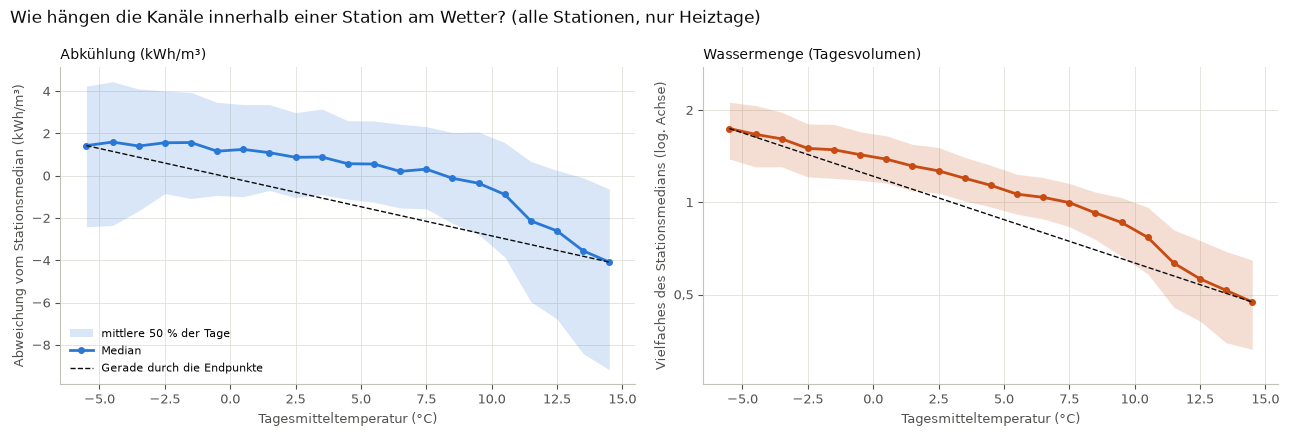

In [3]:
klassen = np.arange(np.floor(modelltage["t_mittel_c"].min()), T_HEIZGRENZE + 1)
klasse = pd.cut(modelltage["t_mittel_c"], klassen)


def formprofil(kanal):
    """Median und mittlere 50 % je 1-K-Klasse, jede Station um ihren eigenen Median verschoben."""
    zentriert = modelltage[kanal] - modelltage.groupby("zaehler")[kanal].transform("median")
    g = zentriert.groupby(klasse, observed=True)
    profil = pd.DataFrame({"n": g.size(), "p25": g.quantile(0.25), "p50": g.median(), "p75": g.quantile(0.75)})
    profil = profil[profil["n"] >= 50]
    profil["t"] = [iv.mid for iv in profil.index]
    return profil.reset_index(drop=True)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    p = formprofil(kanal)
    umrechnen = np.exp if kanal == "log_volumen" else (lambda w: w)
    farbe = FARBE_KANAL[kanal]
    if kanal == "log_volumen":
        ax.set_yscale("log")
    ax.fill_between(p["t"], umrechnen(p["p25"]), umrechnen(p["p75"]), color=farbe, alpha=0.18, linewidth=0,
                    label="mittlere 50 % der Tage")
    ax.plot(p["t"], umrechnen(p["p50"]), color=farbe, linewidth=2, marker="o", markersize=4, label="Median")
    if len(p) >= 2:
        gerade = np.interp(p["t"], p["t"].iloc[[0, -1]], p["p50"].iloc[[0, -1]])
        ax.plot(p["t"], umrechnen(gerade), color=TINTE, linestyle="--", linewidth=1,
                label="Gerade durch die Endpunkte")
    if kanal == "log_volumen":
        vielfaches = [0.25, 0.5, 1, 2, 4]
        ax.set_yticks(vielfaches, [f"{v:g}".replace(".", ",") for v in vielfaches])
        ax.minorticks_off()
        ax.set_ylim(np.exp(p["p25"].min()) / 1.3, np.exp(p["p75"].max()) * 1.3)
        ax.set_ylabel("Vielfaches des Stationsmedians (log. Achse)", fontsize=9, color=TINTE_LEISE)
    else:
        ax.set_ylabel("Abweichung vom Stationsmedian (kWh/m³)", fontsize=9, color=TINTE_LEISE)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Tagesmitteltemperatur (°C)", fontsize=9, color=TINTE_LEISE)
    stil(ax)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Wie hängen die Kanäle innerhalb einer Station am Wetter? (alle Stationen, nur Heiztage)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- **Abkühlung (links):** Liegt die Medianlinie nahe an der gestrichelten Geraden, reicht für die Abkühlung
  eine Gerade. Erwartung aus NB 08: Sie fällt mit wärmerem Wetter um etwa 0,6 bis 0,7 kWh/m³ je Kelvin.
- **Wassermenge (rechts):** Hier ist eine Krümmung zu erwarten. Der Wärmebedarf wächst ungefähr mit dem
  Abstand zwischen Raum- und Außentemperatur, bei mildem Wetter bleibt aber ein Sockel aus Warmwasser und
  Zirkulation. Steil bei Kälte, flach bei mildem Wetter.
- Ist eine Kurve deutlich krumm, braucht dieser Kanal die **Klassenkennlinie** statt der Geraden (Abschnitt 5,
  Einstellung `FORM_JE_KANAL`). Eine Gerade durch eine krumme Kurve liegt in Kälteperioden immer auf derselben
  Seite und erzeugt dort Scheinalarme in eine Richtung. Das hat der Test an synthetischen Daten beim Bau dieses
  Notebooks gezeigt.
- Die **Breite des Bandes** ist die Schwankung von Tag zu Tag, die das Wetter nicht erklärt. Je breiter, desto
  größer muss eine Veränderung sein, bevor das Modell sie sicher erkennt.
- An den Rändern (sehr kalt, knapp unter 15 °C) gibt es wenige Tage, dort ist die Linie unruhiger.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 3 · Begehungen laden

**Wofür die Begehungen hier gebraucht werden**
- Die Referenz einer Station soll **vor** ihrer ersten Begehung enden (Abschnitt 4). Sonst lernt das Modell
  den Zustand nach dem Eingriff als normal, und die Wirkung verschwindet aus den Residuen.
- In Abschnitt 10 und 11 sind die Termine der Prüfstein für das Modell.

**Wie**
- Die Logik ist eine **Kopie** aus `src/load_begehungen.py` (Begehungstabelle lesen, Adresse → Zählernummer
  über `Zuordnung.xlsx`) und `src/befundcodes.py` (Freitext → mechanischer Befund), Stand 14.10.2026.
- Dadurch bekommen dieselben Begehungen dieselben Zähler wie in NB 03, 14 und 15, ohne `src` zu importieren.
- Ändert sich dort etwas, zum Beispiel neue Freitext-Muster, muss es hier nachgezogen werden.

In [4]:
def adresse_norm(s):
    """Wie _normalize_address in src/load_data.py plus Tippfehler aus src/load_begehungen.py.

    Bewusst hier dupliziert (wie in NB 06), damit das Notebook eigenstaendig bleibt.
    """
    if not isinstance(s, str):
        return ""
    t = s.lower().strip().replace("ß", "ss")
    t = t.replace("ä", "ae").replace("ö", "oe").replace("ü", "ue")
    t = re.sub(r"\.", "", t)
    t = re.sub(r"str(asse)?\b", "strasse", t)
    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"[^a-z0-9 \-]", "", t)
    t = re.sub(r"(\d)\s+([a-z])\b", r"\1\2", t)
    t = re.sub(r"\s*-\s*", "-", t)
    return t.strip().replace("fleiderstrasse", "fliederstrasse")


# Begehungstabelle: zweizeiliger Kopf (Gruppe, darunter von/bis bzw. alt/neu), Daten ab Zeile 4
dateien = sorted(RAW.glob("*Ergebnis_Optimierung_FW*.xlsx"))
if not dateien:
    raise FileNotFoundError(f"keine Begehungstabelle unter {RAW}")
roh = pd.read_excel(dateien[0], sheet_name="Tabelle1", header=None)
kopf = [f"{a}|{b}" if pd.notna(b) else str(a) for a, b in zip(roh.iloc[0].ffill(), roh.iloc[1])]
koerper = roh.iloc[3:].reset_index(drop=True)


def spalte(muster):
    """Erste Spalte, deren Kopf das Muster enthaelt (wie position() in src/load_begehungen.py)."""
    for i, k in enumerate(kopf):
        if muster in k:
            return koerper.iloc[:, i]
    raise KeyError(f"Spalte {muster!r} nicht in der Begehungstabelle")


beg = pd.DataFrame({
    "datum": pd.to_datetime(spalte("Datum"), errors="coerce"),
    "strasse": spalte("Straßenname"),
    "hausnr": spalte("Hausnummer"),
    "kategorie": spalte("Kategorie"),
    "sonstiges": spalte("Sonstiges"),
})
beg = beg[beg["strasse"].notna()].copy()
beg["key"] = (beg["strasse"].astype(str).str.strip() + " "
              + beg["hausnr"].astype(str).str.strip()).map(adresse_norm)

# Zuordnung.xlsx: ein Blatt je Jahr; 2024/2025 mit "Abnahmestelle", 2026 mit Strasse und Hausnummer getrennt
teile = []
for blatt in pd.ExcelFile(ZUORDNUNG_PATH).sheet_names:
    z = pd.read_excel(ZUORDNUNG_PATH, sheet_name=blatt)
    sp = list(z.columns)
    if len(sp) > 3 and "Hausnr" in str(sp[2]):
        adresse = z[sp[1]].astype(str).str.strip() + " " + z[sp[2]].astype(str).str.strip()
    else:
        adresse = z[sp[2]]
    teile.append(pd.DataFrame({"zaehler": pd.to_numeric(z[sp[0]], errors="coerce"), "adresse": adresse}))
zuordnung = pd.concat(teile, ignore_index=True).dropna()
zuordnung["zaehler"] = zuordnung["zaehler"].astype(int)
zuordnung["key"] = zuordnung["adresse"].map(adresse_norm)
zuordnung = zuordnung[zuordnung["key"].str.len() > 3]

# Je Adresse ein Zaehler; bei Zaehlerwechsel bevorzugt einer mit Tageswerten (wie in src)
mit_tageswerten = set(tage["zaehler"])
zaehler_je_adresse = {}
for key, gruppe in zuordnung.groupby("key"):
    kandidaten = sorted(set(gruppe["zaehler"]))
    mit_daten = [k for k in kandidaten if k in mit_tageswerten]
    zaehler_je_adresse[key] = mit_daten[0] if mit_daten else kandidaten[0]
beg["zaehler"] = beg["key"].map(zaehler_je_adresse)

/Users/seb/miniconda3/envs/projektseminar/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


In [5]:
# Kopie aus src/befundcodes.py (Stand 14.10.2026): nur die fuenf Kategorien, die NB 15
# als "mechanischer Befund" zusammenfasst. Je Kategorie: Treffermuster, Veto direkt
# dahinter ("schmutzfaenger fast leer"), Veto direkt davor ("schwerkraft zirkulation").
VETO_FENSTER, VETO_FENSTER_DAVOR = 25, 20
MECHANISCHE_BEFUNDE = {
    "schmutzfaenger": ([r"schmutzfaenger", r"schmutzfilter", r"\bfilter\b"],
                       [r"^ (fast )?leer", r"^ sauber", r"^ passt", r"^ in ordnung"], []),
    "ventil_stellantrieb": ([r"regelventil", r"stellventil", r"stellmot\w*", r"stellant\w*",
                             r"\bamv\s*\d", r"\bventile?\b", r"regler schliesst nicht"],
                            [r"^ passt", r"^ in ordnung"], []),
    "pumpe": ([r"heizkreispumpe", r"rw pumpoe", r"rw pumpe", r"(?<!zirk )pumpe defekt",
               r"pumpe laeuft nicht"],
              [r"^ passt", r"^ in ordnung"], []),
    "zirkulation": ([r"zirk\w* pumpe", r"zirkulationspumpe", r"\bzirk\b", r"\bzirkulation",
                     r"fehlzirkulation"],
                    [r"^ passt", r"^ in ordnung"], [r"schwerkraft\s*$", r"natur\w*\s*$"]),
    "hydraulik_volumenstrom": ([r"volumenstrom", r"durchfluss", r"hydraulisch\w* abgleich",
                                r"hydraulik nicht richtig", r"druck ist zu niedrig",
                                r"hoher sekundaerdruck", r"eingeregelt"],
                               [r"^ passt", r"^ in ordnung"], []),
}
UMLAUTE = str.maketrans({"ä": "ae", "ö": "oe", "ü": "ue", "ß": "ss", "Ä": "ae", "Ö": "oe", "Ü": "ue"})


def normalisiere(text):
    """Kleinschreibung, Umlaute aufgeloest, Leerraum zusammengezogen."""
    if text is None or (isinstance(text, float) and pd.isna(text)):
        return ""
    return re.sub(r"\s+", " ", str(text).translate(UMLAUTE).lower()).strip()


def trifft(text, muster, veto_danach, veto_davor):
    """Trifft das Muster, ohne dass ein Veto direkt dahinter oder davor den Treffer aufhebt?"""
    for fund in re.finditer(muster, text):
        rechts = text[fund.end():fund.end() + VETO_FENSTER]
        links = text[max(0, fund.start() - VETO_FENSTER_DAVOR):fund.start()]
        if any(re.search(v, rechts) for v in veto_danach):
            continue
        if any(re.search(v, links) for v in veto_davor):
            continue
        return True
    return False


def mechanischer_befund(text):
    s = normalisiere(text)
    return any(trifft(s, m, danach, davor)
               for treffer, danach, davor in MECHANISCHE_BEFUNDE.values()
               for m in treffer)


beg["mechanisch"] = beg["sonstiges"].map(mechanischer_befund).astype(bool)
beg["datum"] = beg["datum"].dt.normalize()

# Termine je Zaehler (fuer die Referenz) und Faelle: eine Zeile je Zaehler und Termin
mit_termin = beg.dropna(subset=["datum", "zaehler"]).copy()
mit_termin["zaehler"] = mit_termin["zaehler"].astype(int)
termine = {zaehler: sorted(set(g["datum"])) for zaehler, g in mit_termin.groupby("zaehler")}
faelle_alle = (mit_termin.groupby(["zaehler", "datum"])
               .agg(kategorie=("kategorie", "first"), mechanisch=("mechanisch", "any"))
               .reset_index())

print(f"Begehungen in der Tabelle : {len(beg)}")
print(f"  mit Freitext            : {int((beg['sonstiges'].map(normalisiere) != '').sum())}")
print(f"  mit Datum               : {int(beg['datum'].notna().sum())}")
print(f"  mit Zaehlernummer       : {int(beg['zaehler'].notna().sum())}")
print(f"  mit Tageswerten (NB 06) : {int(beg['zaehler'].isin(mit_tageswerten).sum())}")
print(f"  mit mechanischem Befund : {int(beg['mechanisch'].sum())}")
print(f"Termine (Zaehler x Datum) : {len(faelle_alle)} an {faelle_alle['zaehler'].nunique()} Zaehlern")
display(beg["kategorie"].value_counts(dropna=False).to_frame("Begehungen"))
display(beg["datum"].dt.to_period("Q").value_counts().sort_index().to_frame("Begehungen je Quartal"))

Begehungen in der Tabelle : 66
  mit Freitext            : 57
  mit Datum               : 58
  mit Zaehlernummer       : 66
  mit Tageswerten (NB 06) : 59
  mit mechanischem Befund : 22
Termine (Zaehler x Datum) : 58 an 56 Zaehlern


,Begehungen
kategorie,
mittlere,36
viele,21
geringe,5
keine,4


,Begehungen je Quartal
datum,
2024Q3,36
2024Q4,17
2025Q1,1
2025Q3,4


**Was machen die beiden Zellen?**
- lesen die Begehungstabelle mit ihrem zweizeiligen Kopf. Die Spalten werden über ihre Überschrift gefunden,
  nicht über die Position, weil die Tabelle zwischen Datenlieferungen ihr Layout geändert hat
- verbinden Adresse → Zählernummer über alle Jahresblätter von `Zuordnung.xlsx`. Hat eine Adresse über die
  Jahre mehrere Zähler, wird einer mit Tageswerten genommen
- kodieren den Freitext: **mechanischer Befund** = Schmutzfänger, Ventil/Stellantrieb, Pumpe, Zirkulation oder
  Hydraulik/Volumenstrom, jeweils mit Verneinungsprüfung („Schmutzfänger fast leer“ zählt nicht)
- `termine`: je Zähler die Begehungsdaten; `faelle_alle`: eine Zeile je Zähler und Termin

**Warum „mechanisch“ extra?**
- NB 15: Der Kennlinienmonitor trifft mechanische Eingriffe (10 von 19) deutlich besser als den Rest.
  Physikalisch plausibel: Ein getauschter Stellmotor ändert die Hydraulik, eine verschobene Heizzeit ändert die
  Tagesbilanz kaum.
- Damit die Ergebnisse vergleichbar bleiben, gilt hier dieselbe Einteilung.

**Worauf achten**
- Die Zahlen oben sollten zu NB 03 und 15 passen: 66 Begehungen, 57 mit Freitext, der Großteil im 3. Quartal 2024.
- Mehrere Begehungen an derselben Station zählen als getrennte Fälle. Sie sind nicht unabhängig.
- Zählerwechsel: Tauschdaten fehlen (NB 15, Abschnitt 8). Wo eine Adresse mehrere Zähler hat, wird der Zähler
  mit Tageswerten genommen.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 4 · Referenzzeitraum je Station

**Die Idee:** Das Modell muss wissen, was für diese Station normal ist. Dafür bekommt jede Station einen
Referenzzeitraum: ihr **erstes Jahr** mit verwendbaren Heiztagen.

**Warum ein ganzes Jahr?**
- Ein Jahr enthält kalte Wintertage und milde Herbst- und Frühjahrstage. Die Kennlinie wird über den ganzen
  Temperaturbereich gelernt und muss später kaum über ihre Daten hinaus verlängert werden.
- Ein halbes Jahr ab Oktober würde zum Beispiel nur den Winter abdecken.

**Warum vor der ersten Begehung?**
- Liegt die Begehung im Referenzzeitraum, lernt das Modell den Zustand vorher und nachher als „normal“.
  Die Wirkung wäre dann unsichtbar.
- Deshalb endet die Referenz spätestens 14 Tage vor der ersten Begehung, die nach dem Start der Station liegt.
  Das ist kein Datenleck: Die ÜZ weiß im Betrieb auch, wann sie vor Ort war.

**Wichtig: Referenz heißt nicht gesund.**
- Lief eine Station schon im ersten Jahr schlecht (der Ventilfall 68956351), dann ist „schlecht“ ihr
  Normalzustand.
- Das Modell erkennt **Veränderungen**, nicht schlechte Stationen. Für dauerhaft schlechte Stationen gibt es
  den Flottenvergleich in Abschnitt 12.

**Wann eine Station nicht überwacht wird**
- weniger als 60 verwendbare Heiztage in der Referenz
- Temperaturspanne der Referenz unter 8 K
- keine verwendbaren Heiztage nach der Referenz

In [6]:
zeilen = []
for zaehler, d in modelltage.groupby("zaehler"):
    start = d["datum"].min()
    ende = start + pd.Timedelta(days=REF_KALENDERTAGE)
    ende_grund = "ein Jahr"
    spaeter = [t for t in termine.get(zaehler, []) if t > start]
    if spaeter and spaeter[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG) < ende:
        ende = spaeter[0] - pd.Timedelta(days=ABSTAND_BEGEHUNG)
        ende_grund = "vor Begehung"
    ref = d[(d["datum"] >= start) & (d["datum"] < ende)]
    spanne = ref["t_mittel_c"].max() - ref["t_mittel_c"].min() if len(ref) else 0.0
    nachher = int((d["datum"] >= ende).sum())
    if len(ref) < MIN_REF_TAGE:
        status = "zu wenige Referenztage"
    elif spanne < MIN_REF_SPANNE_K:
        status = "zu kleine Temperaturspanne"
    elif nachher == 0:
        status = "keine Tage nach der Referenz"
    else:
        status = "ok"
    zeilen.append({"zaehler": zaehler, "ref_start": start, "ref_ende": ende, "ende_grund": ende_grund,
                   "ref_tage": len(ref), "ref_spanne_k": spanne, "ueberwachte_tage": nachher,
                   "status": status})
referenz = pd.DataFrame(zeilen).set_index("zaehler")
stationen = referenz.index[referenz["status"] == "ok"].tolist()

display(referenz["status"].value_counts().to_frame("Stationen"))
ok = referenz.loc[stationen]
print(f"ueberwacht: {len(stationen)} Stationen")
print(f"  Referenz endet nach einem Jahr: {int((ok['ende_grund'] == 'ein Jahr').sum())}, "
      f"vor einer Begehung: {int((ok['ende_grund'] == 'vor Begehung').sum())}")
print(f"  Referenztage je Station: Median {ok['ref_tage'].median():.0f} "
      f"(min {ok['ref_tage'].min()}, max {ok['ref_tage'].max()})")
print(f"  Temperaturspanne der Referenz: Median {ok['ref_spanne_k'].median():.1f} K")
print(f"  ueberwachte Heiztage je Station: Median {ok['ueberwachte_tage'].median():.0f}")
display(ok["ref_ende"].dt.to_period("Q").value_counts().sort_index().to_frame("Referenz endet im Quartal"))

,Stationen
status,
ok,89
keine Tage nach der Referenz,5


ueberwacht: 89 Stationen
  Referenz endet nach einem Jahr: 70, vor einer Begehung: 19
  Referenztage je Station: Median 228 (min 84, max 240)
  Temperaturspanne der Referenz: Median 19.9 K
  ueberwachte Heiztage je Station: Median 241


,Referenz endet im Quartal
ref_ende,
2022Q4,43
2023Q1,1
2023Q2,1
2024Q1,1
2024Q3,28
2024Q4,12
2025Q1,3


**Was macht die Zelle?**
- legt je Station fest: Start = erster verwendbarer Heiztag, Ende = ein Jahr später oder 14 Tage vor der
  ersten Begehung, je nachdem, was früher kommt
- zählt die Referenztage, ihre Temperaturspanne und die Tage danach, die überwacht werden können
- `stationen` ist die Liste der Stationen mit Status `ok`. Nur mit ihnen rechnet der Rest des Notebooks

**Wie man das Ergebnis liest**
- Die Statustabelle zeigt, wie viele Stationen aus welchem Grund herausfallen.
- Die Quartalstabelle zeigt, wann die Überwachung beginnt. Erwartet sind zwei Gruppen passend zu den zwei
  Ausbauwellen aus NB 00 (Start 4. Quartal 2021 bzw. 2. Quartal 2023), also Ende der Referenz Ende 2022 bzw.
  Mitte 2024.
- Die Begehungen vom September 2024 liegen damit bei allen Stationen im überwachten Zeitraum.

**Stellschrauben**
- `REF_KALENDERTAGE` kürzer → mehr überwachte Tage, aber weniger Temperaturbereich in der Referenz.
- `MIN_REF_TAGE` kleiner → mehr Stationen, unsicherere Kennlinien.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 5 · Das Modell: eine Kennlinie je Station und Kanal

**Die Idee:** Aus den Referenztagen einer Station wird gelernt, welchen Wert sie bei welcher
Tagesmitteltemperatur T typischerweise hat. Diese **Kennlinie** liefert für jeden späteren Tag die Erwartung.

**Zwei Formen, je Kanal wählbar** (`FORM_JE_KANAL`)

| Form | Wie | Gut für | Startwert für |
|---|---|---|---|
| `gerade` | Erwartung = a + b · T, Theil-Sen-Gerade durch die Referenztage | Zusammenhänge, die im Bild aus Abschnitt 2 gerade aussehen | Abkühlung |
| `klassen` | Median der Referenztage je 2-K-Temperaturklasse, die Mediane mit Linien verbunden | krumme Zusammenhänge | Wassermenge |

- Bei der Geraden ist **a** der erwartete Wert bei 0 °C und **b** die Änderung je Kelvin wärmer.
- Bei der Klassenkennlinie ist jeder Punkt der Median der Referenztage in einer Temperaturklasse (zum Beispiel
  2 bis 4 °C), an der mittleren Temperatur dieser Tage. Klassen mit weniger als 8 Referenztagen fallen weg,
  ihre Nachbarn werden direkt verbunden. Kälter oder wärmer als alle Referenztage gilt der Wert der äußersten
  Klasse.
- Dazu kommt je Kanal die **Streuung s**: wie weit die Station an einem typischen Referenztag von ihrer
  Kennlinie entfernt lag.

**Warum nicht immer die Klassenkennlinie?**
- Sie passt sich jeder Form an, aber jeder ihrer Punkte stammt aus nur 20 bis 30 Tagen und wackelt
  entsprechend. Eine Gerade nutzt alle Tage für zwei Zahlen und ist deshalb ruhiger, wenn der Zusammenhang
  wirklich gerade ist.
- Beim Test an synthetischen Daten gab es mit der Geraden für die (dort geraden) Abkühlungswerte weniger
  Fehlalarme. Für die (krumme) Wassermenge war die Gerade dagegen schief: fast alle Fehlalarme zeigten nach
  unten. Mit der Klassenkennlinie waren sie ausgewogen.
- Die Gerade hat außerdem lesbare Zahlen: Die Abkühlungsgerade ist dieselbe Form wie in NB 08 und auf der
  ÜZ-Folie.

**Warum Theil-Sen statt der üblichen Regression?**
- Die übliche Regression (kleinste Quadrate) quadriert die Abstände. Ein einziger kaputter Tag, etwa ein
  Zählersprung oder ein Tag Leerstand, zieht die Gerade dadurch spürbar zu sich.
- Theil-Sen nimmt für **jedes Paar von Tagen** die Steigung der Verbindungslinie und davon den **Median**.
  Einzelne Ausreißer ändern den Median kaum. Die Gerade hält, solange weniger als etwa ein Viertel der Tage
  Ausreißer sind.
- Aus demselben Grund nimmt die Klassenkennlinie den Median und nicht den Mittelwert jeder Klasse.

**Warum die Streuung s mit dem MAD?**
- MAD = Median der Abstände zum Median. Mal 1,4826 genommen ist er bei normalverteilten Daten genauso groß wie
  die Standardabweichung, reagiert aber wie der Median kaum auf Ausreißer.
- Mit s wird jeder Tag in „typischen Tagesschwankungen dieser Station“ gemessen (z-Wert). Eine ruhige Station
  schlägt dadurch schon bei kleineren Abweichungen an als eine unruhige. Das ist fair, weil für beide
  dieselbe Schwelle gilt.

**Warum die Streuung wegen der Autokorrelation vergrößert wird**
- Weicht eine Station heute nach oben ab, tut sie das morgen oft auch: Das Gebäude ist träge, Wetterlagen
  halten mehrere Tage, Bewohner haben Gewohnheiten. Das misst die **Autokorrelation φ** der Residuen
  (0 = unabhängig, 1 = morgen genau wie heute).
- Der CUSUM in Abschnitt 7 zählt jeden Tag als neue, unabhängige Information. Bei φ = 0,5 sind zehn
  Abweichungen in Folge aber viel weniger überraschend als zehn unabhängige. Ohne Korrektur gibt es dann viel
  mehr Fehlalarme. Beim Test an synthetischen Daten alarmierte über die Hälfte der Kontrollstationen in jedem
  Zweimonatsfenster.
- Die Standardkorrektur für diesen Fall: Die Streuung wird mit **√((1 + φ) / (1 − φ))** multipliziert. So viel
  größer ist die Schwankung einer Summe über viele Tage, wenn die Tage so zusammenhängen. Bei φ = 0,5 ist der
  Faktor √3 ≈ 1,7.
- Preis: Eine kleine echte Verschiebung braucht entsprechend länger bis zum Alarm. Das ist ehrlich, denn
  zusammenhängende Tage enthalten weniger Information als unabhängige.
- Abschalten mit `AUTOKORRELATION_BERUECKSICHTIGEN = False`.

In [7]:
def lerne_kennlinie(form, t, y):
    """Lernt aus Referenztagen die Kennlinie Temperatur -> erwarteter Wert.

    "gerade": Theil-Sen-Gerade (Median der Steigungen aller Tagespaare).
    "klassen": Median je Temperaturklasse an der mittleren Temperatur der Klasse.
    Hat die Referenz weniger als zwei brauchbare Klassen, wird ersatzweise die Gerade genommen.
    """
    t, y = np.asarray(t, dtype=float), np.asarray(y, dtype=float)
    if form == "klassen":
        tab = (pd.DataFrame({"klasse": np.floor(t / KLASSENBREITE_K), "t": t, "y": y})
               .groupby("klasse").agg(n=("y", "size"), t=("t", "median"), y=("y", "median")))
        tab = tab[tab["n"] >= MIN_TAGE_JE_KLASSE]
        if len(tab) >= 2:
            return {"form": "klassen", "stuetz_t": tab["t"].to_numpy(), "stuetz_y": tab["y"].to_numpy()}
    b, a, _, _ = stats.theilslopes(y, t)
    return {"form": "gerade", "a": a, "b": b}


def kennlinienwert(kennlinie, t):
    """Erwarteter Wert der Kennlinie bei Temperatur t."""
    t = np.asarray(t, dtype=float)
    if kennlinie["form"] == "gerade":
        return kennlinie["a"] + kennlinie["b"] * t
    return np.interp(t, kennlinie["stuetz_t"], kennlinie["stuetz_y"])


def robuste_streuung(r):
    """1,4826 * MAD: robust wie der Median, bei Normalverteilung gleich der Standardabweichung."""
    r = np.asarray(r, dtype=float)
    return 1.4826 * np.median(np.abs(r - np.median(r)))


def autokorrelation(rest):
    """Korrelation der Residuen zweier aufeinanderfolgender verwendbarer Heiztage."""
    if len(rest) < 3 or np.std(rest) == 0:
        return 0.0
    return float(np.corrcoef(rest[:-1], rest[1:])[0, 1])


def referenztage(zaehler):
    d = modelltage[modelltage["zaehler"] == zaehler]
    return d[(d["datum"] >= referenz.at[zaehler, "ref_start"]) & (d["datum"] < referenz.at[zaehler, "ref_ende"])]


modelle, zeilen = {}, []
for zaehler in stationen:
    ref = referenztage(zaehler)
    t = ref["t_mittel_c"].to_numpy()
    for kanal in KANAELE:
        y = ref[kanal].to_numpy()
        kennlinie = lerne_kennlinie(FORM_JE_KANAL[kanal], t, y)
        rest = y - kennlinienwert(kennlinie, t)
        s = max(robuste_streuung(rest), 1e-6)
        phi = autokorrelation(rest)
        phi_korrektur = min(max(phi, 0.0), PHI_MAX)
        faktor = np.sqrt((1 + phi_korrektur) / (1 - phi_korrektur)) if AUTOKORRELATION_BERUECKSICHTIGEN else 1.0
        modelle[(zaehler, kanal)] = {"kennlinie": kennlinie, "s": s, "s_eff": s * faktor}
        zeilen.append({"zaehler": zaehler, "kanal": kanal, "form": kennlinie["form"],
                       "b": kennlinie.get("b", np.nan),
                       "klassen": len(kennlinie.get("stuetz_t", [])) or np.nan,
                       "kalt_minus_mild": float(kennlinienwert(kennlinie, 0.0) - kennlinienwert(kennlinie, 10.0)),
                       "s": s, "autokorrelation": phi, "faktor": faktor})
parameter = pd.DataFrame(zeilen)

zusammenfassung = parameter.groupby("kanal").agg(
    Stationen=("zaehler", "size"),
    davon_gerade=("form", lambda f: int((f == "gerade").sum())),
    b_median=("b", "median"),
    klassen_median=("klassen", "median"),
    kalt_minus_mild_median=("kalt_minus_mild", "median"),
    anteil_kalt_hoeher=("kalt_minus_mild", lambda x: (x > 0).mean()),
    s_median=("s", "median"),
    autokorrelation_median=("autokorrelation", "median"),
    faktor_median=("faktor", "median"),
).reindex(list(KANAELE))
display(zusammenfassung.round(3))
km_vol = zusammenfassung.at["log_volumen", "kalt_minus_mild_median"]
s_vol = zusammenfassung.at["log_volumen", "s_median"]
print(f"Wassermenge: bei 0 °C im Median {prozent(km_vol):+.0f} % mehr Wasser als bei 10 °C, "
      f"typische Tagesstreuung rund {prozent(s_vol):.0f} %")

,Stationen,davon_gerade,b_median,klassen_median,kalt_minus_mild_median,anteil_kalt_hoeher,s_median,autokorrelation_median,faktor_median
kanal,,,,,,,,,
kwh_pro_m3,89,89,-0.327,NaN,3.273,0.775,2.461,0.682,2.299
log_volumen,89,0,NaN,8.0,0.613,0.910,0.201,0.591,1.972


Wassermenge: bei 0 °C im Median +85 % mehr Wasser als bei 10 °C, typische Tagesstreuung rund 22 %


**Was macht die Zelle?**
- `lerne_kennlinie()` lernt aus den Referenztagen die Gerade oder die Klassenkennlinie, `kennlinienwert()` liest die
  Erwartung für eine beliebige Temperatur ab
- je Station und Kanal: Kennlinie lernen, Streuung s, Autokorrelation φ und Korrekturfaktor bestimmen
- speichert alles in `modelle` (für die Rechnung) und als Tabelle in `parameter` (zum Ansehen)

**Wie man die Tabelle liest**
- `davon_gerade`: wie viele Stationen tatsächlich eine Gerade haben. Bei der Wassermenge sollte das 0 sein. Ist
  es größer, hatten diese Stationen zu wenige Referenztage je Klasse, und es wurde ersatzweise die Gerade
  genommen.
- `b_median` (nur Gerade): Änderung der kWh/m³ je Kelvin wärmer. NB 08 fand über alle Stationen −0,6 bis −0,7,
  hier steht dieselbe Größe je Station.
- `klassen_median` (nur Klassenkennlinie): wie viele Stützpunkte die Kennlinie typischerweise hat.
- `kalt_minus_mild_median`: Erwartung bei 0 °C minus Erwartung bei 10 °C, für beide Formen gleich gerechnet.
  Abkühlung in kWh/m³, Wassermenge in Log-Einheiten (die Zeile unter der Tabelle rechnet in Prozent um).
- `anteil_kalt_hoeher`: Anteil der Stationen, die bei 0 °C mehr liefern als bei 10 °C. Bei der Wassermenge
  sollte das fast 1 sein. Eine Station, die bei Kälte **weniger** Wasser zieht, ist schon für sich ein Befund
  (Leerstand im Winter, Durchfluss unabhängig vom Wetter).
- `s_median`: die typische Tagesschwankung um die Kennlinie (Wassermenge in Log-Einheiten, 0,15 ≈ 15 %). Eine
  Veränderung muss ungefähr diese Größe haben, damit der Alarm sie nach einigen Tagen erkennt.
- `autokorrelation_median` und `faktor_median`: wie stark Folgetage zusammenhängen und um welchen Faktor die
  Streuung deshalb vergrößert wird.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 6 · Wie gut ist die Vorhersage?

- Auf den Referenztagen selbst passt die Kennlinie per Konstruktion. Das sagt nichts.
- Deshalb wird auf Tagen geprüft, die das Modell **nicht kannte**: die ersten bis zu 120 verwendbaren
  Heiztage nach der Referenz, aber vor jeder Begehung.
- Vergleich mit einem naiven Modell, das die Temperatur ignoriert: „immer der Median der Referenz“.
- **Skill = 1 − Fehler Modell / Fehler naiv**, beide als mittlerer absoluter Fehler
  - 0: die Temperatur bringt nichts
  - 0,5: das Modell liegt im Mittel halb so weit daneben wie das naive
  - negativ: das Modell ist schlechter als das naive

,Stationen,Pruef_tage_median,fehler_modell_median,fehler_naiv_median,skill_median,anteil_skill_positiv
kanal,,,,,,
kwh_pro_m3,68,120.0,3.037,2.881,0.016,0.559
log_volumen,68,120.0,0.235,0.321,0.273,0.853


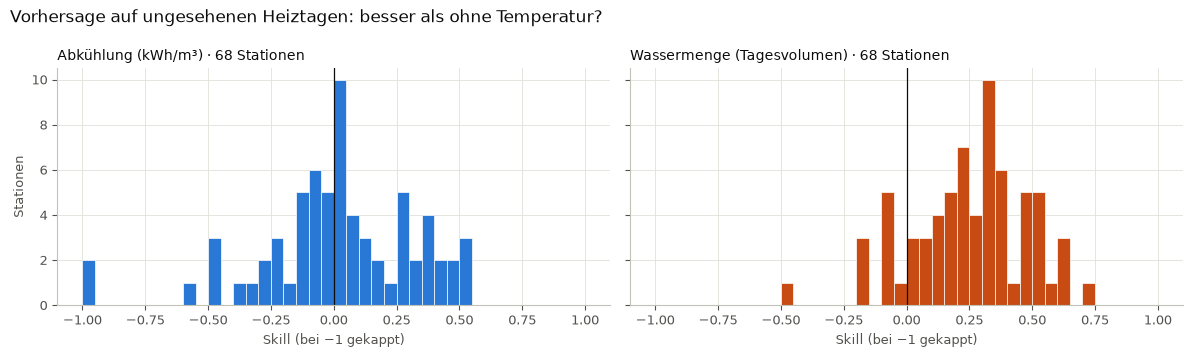

In [8]:
def erwartung(zaehler, kanal, t):
    """Erwarteter Wert eines Kanals bei Tagesmitteltemperatur t."""
    return kennlinienwert(modelle[(zaehler, kanal)]["kennlinie"], t)


zeilen = []
for zaehler in stationen:
    d = modelltage[modelltage["zaehler"] == zaehler]
    ref_ende = referenz.at[zaehler, "ref_ende"]
    pruef = d[d["datum"] >= ref_ende]
    spaeter = [t for t in termine.get(zaehler, []) if t >= ref_ende]
    if spaeter:
        pruef = pruef[pruef["datum"] < spaeter[0] - pd.Timedelta(days=FENSTER_VOR)]
    pruef = pruef.head(PRUEF_TAGE)
    if len(pruef) < MIN_PRUEF_TAGE:
        continue
    ref = referenztage(zaehler)
    for kanal in KANAELE:
        y = pruef[kanal].to_numpy()
        fehler_modell = np.mean(np.abs(y - erwartung(zaehler, kanal, pruef["t_mittel_c"])))
        fehler_naiv = np.mean(np.abs(y - ref[kanal].median()))
        zeilen.append({"zaehler": zaehler, "kanal": kanal, "tage": len(pruef),
                       "fehler_modell": fehler_modell, "fehler_naiv": fehler_naiv,
                       "skill": 1 - fehler_modell / fehler_naiv})
guete = pd.DataFrame(zeilen, columns=["zaehler", "kanal", "tage", "fehler_modell", "fehler_naiv", "skill"])

display(guete.groupby("kanal").agg(
    Stationen=("zaehler", "size"),
    Pruef_tage_median=("tage", "median"),
    fehler_modell_median=("fehler_modell", "median"),
    fehler_naiv_median=("fehler_naiv", "median"),
    skill_median=("skill", "median"),
    anteil_skill_positiv=("skill", lambda x: (x > 0).mean()),
).reindex(list(KANAELE)).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    w = guete.loc[guete["kanal"] == kanal, "skill"].clip(-1, 1)
    ax.hist(w, bins=np.linspace(-1, 1, 41), color=FARBE_KANAL[kanal], edgecolor="white", linewidth=0.5)
    ax.axvline(0, color=TINTE, linewidth=0.9)
    ax.set_title(f"{titel} · {len(w)} Stationen", loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Skill (bei −1 gekappt)", fontsize=9, color=TINTE_LEISE)
    stil(ax)
axes[0].set_ylabel("Stationen", fontsize=9, color=TINTE_LEISE)
fig.suptitle("Vorhersage auf ungesehenen Heiztagen: besser als ohne Temperatur?", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Was macht die Zelle?**
- nimmt je Station die Heiztage direkt nach der Referenz und hört 7 Tage vor der ersten Begehung auf, damit
  keine Wirkung einer Begehung mitgemessen wird
- rechnet den Fehler des Modells und des naiven Modells und daraus den Skill
- Stationen mit weniger als 20 solchen Tagen fehlen in dieser Prüfung, werden aber trotzdem überwacht. Das
  betrifft vor allem Stationen der zweiten Ausbauwelle, deren Referenz kurz vor dem Sommer 2024 endet.

**Wie man das Ergebnis liest**
- Erwartung: Bei der Wassermenge ist der Skill deutlich positiv, weil die Heizlast stark am Wetter hängt. Bei
  der Abkühlung ist er kleiner, weil kWh/m³ schwächer am Wetter hängt.
- `fehler_modell_median` bei der Wassermenge ist in Log-Einheiten: 0,15 heißt rund 15 % typische Abweichung.
- Ein negativer Skill bei einer Station heißt: Entweder hat sie sich seit der Referenz schon verändert (dann
  ist das selbst ein Befund) oder die Temperatur erklärt bei ihr nichts und die Steigung ist Rauschen.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 7 · Abweichung und Alarm: der CUSUM

**Das Problem:** Ein einzelner Tag weit weg von der Erwartung ist meist Zufall: Besuch im Haus, Rundung des
Zählers, ein Wetterumschwung. Interessant wird es, wenn die Station **mehrere Tage hintereinander in dieselbe
Richtung** abweicht.

**Die Lösung: CUSUM** (kumulierte Summe, Page 1954). Am einfachsten als Kontostand vorzustellen:
- Jeden Tag wird der z-Wert des Tages eingezahlt, und es wird eine kleine Gebühr k = 0,5 abgezogen.
- Der Kontostand kann nicht unter null fallen.
- Überschreitet er die Schwelle h = 5, gibt es einen Alarm.
- Es gibt zwei Konten: **S⁺** sammelt Abweichungen nach oben, **S⁻** nach unten.

**Beispiele mit k = 0,5 und h = 5**

| Was die Station tut | Was das Konto tut | Alarm |
|---|---|---|
| Zufall um null (z = +1, −1, +0,3, …) | Plus und Minus gleichen sich aus, die Gebühr hält es bei null | keiner |
| ab heute jeden Tag 1 Streuung höher | wächst um 0,5 pro Tag | nach rund 10 Tagen |
| ab heute jeden Tag 2 Streuungen höher | wächst um 1,5 pro Tag | nach rund 4 Tagen |
| ein Tag z = +6, danach wieder normal | springt auf 5,5, fällt dann wieder | ja, ein Einzeltag dieser Größe reicht |
| Ventilfall, z um +20 | sofort über der Schwelle | am ersten Tag |

**Warum nicht einfach „Alarm, wenn z über 3“?** Das reagiert auf jeden auffälligen Einzeltag und übersieht
kleine, aber dauerhafte Verschiebungen, zum Beispiel jeden Tag z = 1.

**Was die Theorie verspricht:** Bei unabhängigen, normalverteilten Tagen gibt es mit k = 0,5 und h = 5 im
Mittel rund alle 465 Tage einen Fehlalarm (beide Richtungen zusammen). Bei 150 bis 200 verwendbaren Heiztagen
im Jahr wäre das etwa einer alle zwei bis drei Jahre je Kanal. Echte Tage sind nicht unabhängig. Die
vergrößerte Streuung aus Abschnitt 5 gleicht das ungefähr aus, aber nicht exakt. Deshalb wird die tatsächliche
Alarmrate in Abschnitt 9 gemessen und in Abschnitt 11 mit einer Kontrollgruppe verglichen.

**Zwei Zusätze gegenüber dem Lehrbuch**
- **Ein Alarm je Abweichung:** Nach einem Alarm läuft das Konto weiter, ein neuer Alarm in dieselbe Richtung
  kommt erst, wenn es zwischendurch wieder bei null war. Eine dauerhafte Veränderung (repariertes Ventil)
  ergibt so einen Alarm statt einen pro Tag.
- **Deckel bei 10:** Das Konto kann nicht unbegrenzt wachsen. Kehrt die Station zum Normalzustand zurück, ist
  es nach höchstens 10 / 0,5 = 20 Heiztagen wieder bei null.

Gezählt wird nur über verwendbare Heiztage. Sommer und Lücken werden übersprungen, der Kontostand bleibt
dabei erhalten.

Zuerst ein **Spielzeugbeispiel** ohne echte Daten, damit man sieht, wie der Zähler reagiert.

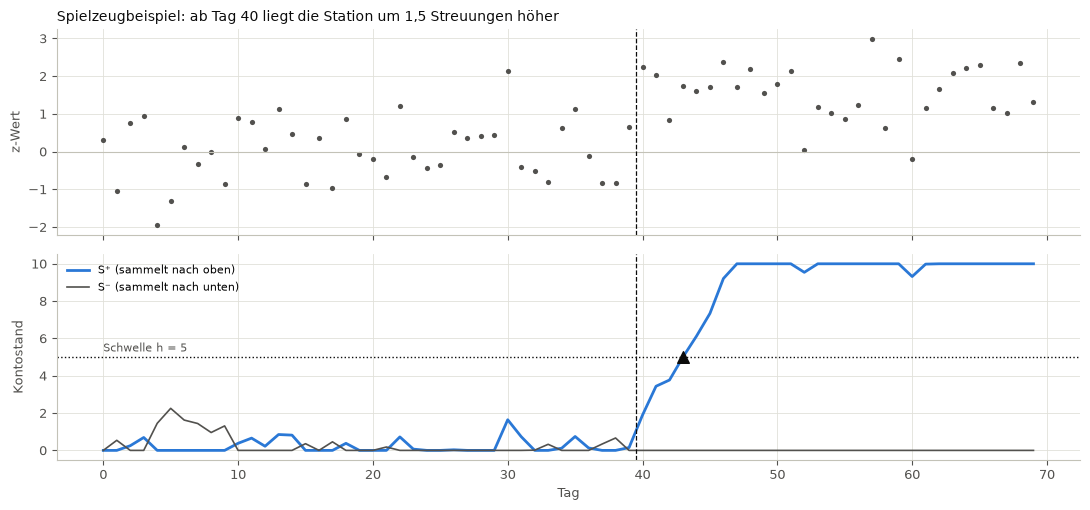

Alarm nach oben an Tag 43, Lauf begann an Tag 39 (5 Tage bis zum Alarm)


In [9]:
def cusum(z, k=CUSUM_K, h=CUSUM_H, deckel=CUSUM_MAX):
    """Zweiseitiger CUSUM ueber eine Folge von z-Werten (Page 1954).

    S+ sammelt Abweichungen nach oben, S- nach unten. Ein Alarm entsteht, wenn ein
    Konto h ueberschreitet; ein weiterer in dieselbe Richtung erst, wenn das Konto
    zwischendurch bei null war. Rueckgabe: S+ und S- je Tag und die Alarme als
    (Index, Richtung, Startindex). Der Startindex ist der erste Tag des Laufs, also
    die Schaetzung, wann die Veraenderung begann.
    """
    s_plus, s_minus = np.zeros(len(z)), np.zeros(len(z))
    sp = sm = 0.0
    an_plus = an_minus = False
    start_plus = start_minus = 0
    alarme = []
    for i, zi in enumerate(z):
        if sp == 0.0:
            start_plus = i
        if sm == 0.0:
            start_minus = i
        sp = min(max(0.0, sp + zi - k), deckel)
        sm = min(max(0.0, sm - zi - k), deckel)
        if sp == 0.0:
            an_plus = False
        if sm == 0.0:
            an_minus = False
        if sp > h and not an_plus:
            alarme.append((i, +1, start_plus))
            an_plus = True
        if sm > h and not an_minus:
            alarme.append((i, -1, start_minus))
            an_minus = True
        s_plus[i], s_minus[i] = sp, sm
    return s_plus, s_minus, alarme


# Spielzeugbeispiel: 40 normale Tage, danach liegt die Station jeden Tag um 1,5 Streuungen hoeher
rng = np.random.default_rng(SEED)
z_spiel = rng.normal(0, 1, 70)
z_spiel[40:] += 1.5
sp_spiel, sm_spiel, alarme_spiel = cusum(z_spiel)
x_spiel = np.arange(len(z_spiel))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
axes[0].scatter(x_spiel, z_spiel, s=14, color=TINTE_LEISE, linewidths=0)
axes[0].axhline(0, color=ACHSE, linewidth=0.8)
axes[0].set_ylabel("z-Wert", fontsize=9, color=TINTE_LEISE)
axes[0].set_title("Spielzeugbeispiel: ab Tag 40 liegt die Station um 1,5 Streuungen höher",
                  loc="left", fontsize=10, color=TINTE)
axes[1].plot(x_spiel, sp_spiel, color=FARBE_KANAL["kwh_pro_m3"], linewidth=2, label="S⁺ (sammelt nach oben)")
axes[1].plot(x_spiel, sm_spiel, color=TINTE_LEISE, linewidth=1.2, label="S⁻ (sammelt nach unten)")
axes[1].axhline(CUSUM_H, color=TINTE, linestyle=":", linewidth=1)
axes[1].text(0, CUSUM_H + 0.3, f"Schwelle h = {CUSUM_H:g}", fontsize=8, color=TINTE_LEISE)
for i, richtung, start in alarme_spiel:
    s_wert = sp_spiel[i] if richtung > 0 else sm_spiel[i]
    axes[1].scatter(i, s_wert, marker="^" if richtung > 0 else "v", s=70, color=TINTE, zorder=3)
axes[1].set_ylabel("Kontostand", fontsize=9, color=TINTE_LEISE)
axes[1].set_xlabel("Tag", fontsize=9, color=TINTE_LEISE)
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
for ax in axes:
    ax.axvline(39.5, color=TINTE, linestyle="--", linewidth=0.9)
    stil(ax)
fig.tight_layout()
plt.show()
for i, richtung, start in alarme_spiel:
    print(f"Alarm {'nach oben' if richtung > 0 else 'nach unten'} an Tag {i}, "
          f"Lauf begann an Tag {start} ({i - start + 1} Tage bis zum Alarm)")

**Wie man das Spielzeugbild liest**
- oben: der z-Wert je Tag. Bis Tag 39 Zufall um null, ab Tag 40 (gestrichelte Linie) im Mittel bei +1,5.
- unten: die beiden Kontostände. Vor Tag 40 bleiben sie klein, weil jeder Tag die Gebühr k bezahlen muss und
  sich Plus und Minus ausgleichen. Ab Tag 40 wächst S⁺ um rund 1 pro Tag (1,5 − 0,5) und überschreitet die
  Schwelle nach ein paar Tagen. Das Dreieck markiert den Alarm.
- Der Alarm nennt auch den **Beginn des Laufs**: den letzten Tag, an dem das Konto bei null stand. Das ist die
  Schätzung, wann die Veränderung angefangen hat.
- Danach bleibt S⁺ am Deckel und meldet keinen neuen Alarm, obwohl die Station weiter höher liegt.

### Dieselbe Rechnung für eine echte Station

`verlauf_station()` macht für eine Station und beide Kanäle:
1. Erwartung aus der Kennlinie für jeden verwendbaren Heiztag
2. Residuum = gemessen − erwartet, z-Wert = Residuum / s
3. CUSUM über die Tage **nach** der Referenz (in der Referenz liegt die Kennlinie per Konstruktion mittendrin)
4. Alarme mit Datum, Richtung und geschätztem Beginn

In [10]:
def verlauf_station(zaehler):
    """Je Kanal und verwendbarem Heiztag: Erwartung, Residuum, z-Wert und CUSUM."""
    d = modelltage[modelltage["zaehler"] == zaehler]
    ref_ende = referenz.at[zaehler, "ref_ende"]
    teile, alarme_station = [], []
    for kanal in KANAELE:
        m = modelle[(zaehler, kanal)]
        v = pd.DataFrame({"zaehler": zaehler, "kanal": kanal,
                          "datum": d["datum"].to_numpy(),
                          "t_mittel_c": d["t_mittel_c"].to_numpy(),
                          "gemessen": d[kanal].to_numpy()})
        v["erwartet"] = erwartung(zaehler, kanal, v["t_mittel_c"])
        v["residuum"] = v["gemessen"] - v["erwartet"]
        v["z"] = v["residuum"] / m["s_eff"]
        v["referenz"] = v["datum"] < ref_ende
        v["s_plus"] = np.nan
        v["s_minus"] = np.nan
        ueberwacht_idx = v.index[~v["referenz"]]
        s_plus, s_minus, al = cusum(v.loc[ueberwacht_idx, "z"].to_numpy())
        v.loc[ueberwacht_idx, "s_plus"] = s_plus
        v.loc[ueberwacht_idx, "s_minus"] = s_minus
        daten = v.loc[ueberwacht_idx, "datum"].to_numpy()
        for i, richtung, start in al:
            alarme_station.append({"zaehler": zaehler, "kanal": kanal,
                                   "datum": pd.Timestamp(daten[i]), "richtung": richtung,
                                   "beginn": pd.Timestamp(daten[start]),
                                   "heiztage_bis_alarm": i - start + 1})
        teile.append(v)
    return pd.concat(teile, ignore_index=True), alarme_station

## 8 · Der bekannte Fall: 68956351

- Bei dieser Station stand das Ventil rund drei Jahre offen. Bei der Begehung am 09.09.2024 wurde der
  Stellmotor getauscht (steht nur im Freitext, NB 15).
- Ihre Referenz ist also der **defekte** Zustand: wenig Abkühlung, viel Wasser.

**Was das Modell zeigen muss**
- vor der Reparatur: ruhig, denn am Defekt hat sich nichts geändert
- nach der Reparatur: Abkühlung deutlich höher (Alarm nach oben), Wassermenge deutlich niedriger (Alarm nach
  unten), und zwar an den ersten Heiztagen danach
- Die Begehung lag Anfang September. Heiztage unter 15 °C gibt es im September nur vereinzelt, die meisten
  kommen ab Oktober. Vorher kann der Alarm nur kommen, wenn es schon kühle Tage gab.

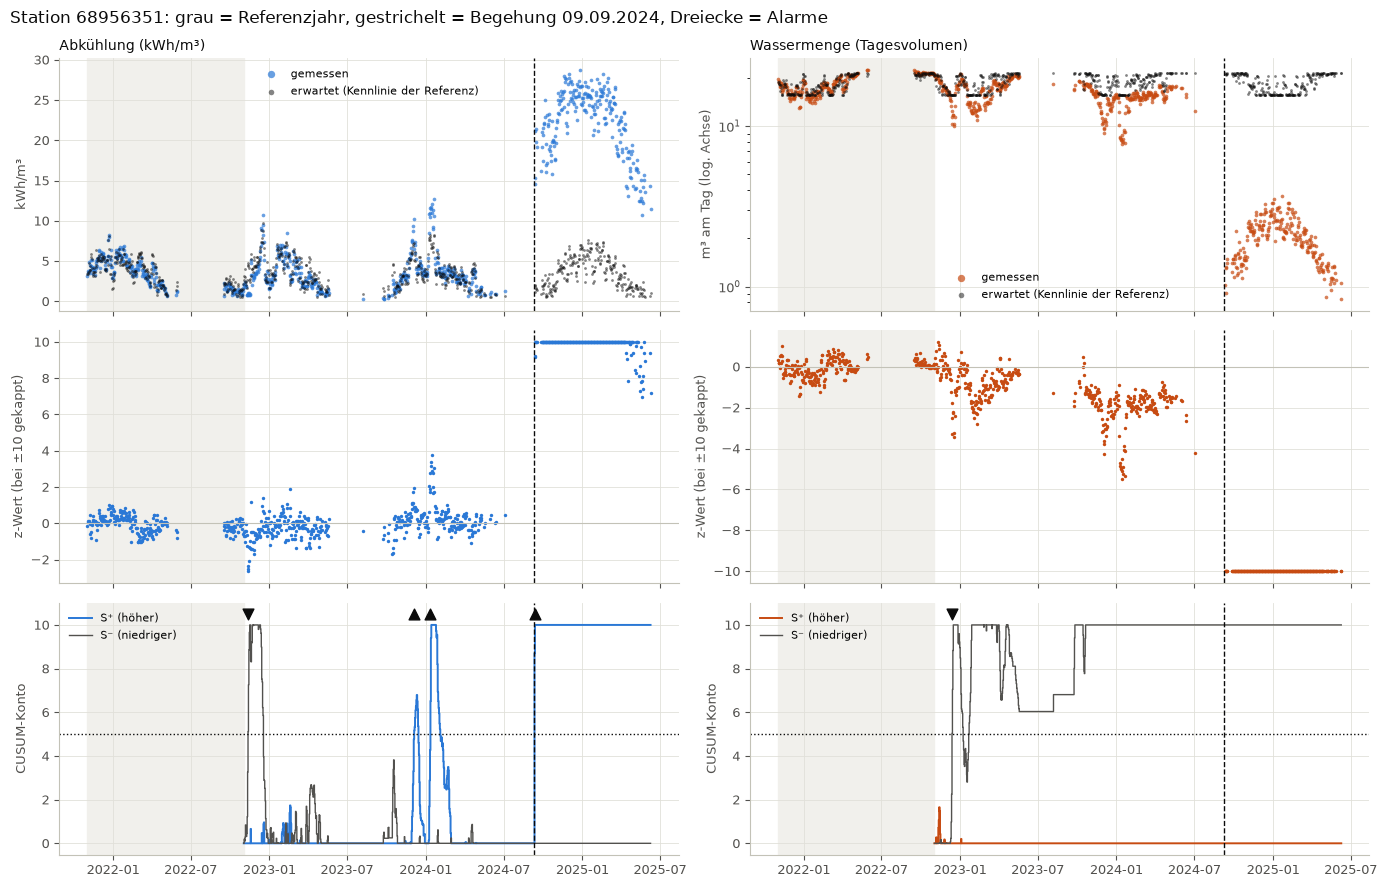

5 Alarme an dieser Station, davon im Fenster [-7, +60] Tage um die Begehung:


,zaehler,kanal,datum,richtung,beginn,heiztage_bis_alarm,tage_nach_begehung
3,68956351,kwh_pro_m3,2024-09-11,hoeher,2024-09-11,1,2


alle Alarme dieser Station:


,zaehler,kanal,datum,richtung,beginn,heiztage_bis_alarm,tage_nach_begehung
0,68956351,kwh_pro_m3,2022-11-12,niedriger,2022-11-03,10,-667
1,68956351,kwh_pro_m3,2023-12-05,hoeher,2023-11-29,7,-279
2,68956351,kwh_pro_m3,2024-01-12,hoeher,2024-01-08,5,-241
3,68956351,kwh_pro_m3,2024-09-11,hoeher,2024-09-11,1,2
4,68956351,log_volumen,2022-12-13,niedriger,2022-12-09,5,-636


In [11]:
if BEISPIEL not in stationen:
    grund = referenz.at[BEISPIEL, "status"] if BEISPIEL in referenz.index else "keine verwendbaren Heiztage"
    print(f"{BEISPIEL} wird nicht ueberwacht: {grund}")
else:
    v_bsp, al_bsp = verlauf_station(BEISPIEL)
    al_bsp = pd.DataFrame(al_bsp)
    fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
    for nr, (kanal, titel) in enumerate(KANAELE.items()):
        v = v_bsp[v_bsp["kanal"] == kanal]
        farbe = FARBE_KANAL[kanal]
        ax = axes[0, nr]
        ax.scatter(v["datum"], anzeige(kanal, v["gemessen"]), s=7, color=farbe, alpha=0.7,
                   linewidths=0, label="gemessen")
        ax.scatter(v["datum"], anzeige(kanal, v["erwartet"]), s=4, color=TINTE, alpha=0.5,
                   linewidths=0, label="erwartet (Kennlinie der Referenz)")
        if kanal == "log_volumen":
            ax.set_yscale("log")
        ax.set_ylabel("m³ am Tag (log. Achse)" if kanal == "log_volumen" else "kWh/m³",
                      fontsize=9, color=TINTE_LEISE)
        ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
        ax.legend(frameon=False, fontsize=8, markerscale=2)
        ax = axes[1, nr]
        ax.scatter(v["datum"], v["z"].clip(-10, 10), s=6, color=farbe, linewidths=0)
        ax.axhline(0, color=ACHSE, linewidth=0.8)
        ax.set_ylabel("z-Wert (bei ±10 gekappt)", fontsize=9, color=TINTE_LEISE)
        ax = axes[2, nr]
        u = v[~v["referenz"]]
        ax.plot(u["datum"], u["s_plus"], color=farbe, linewidth=1.4, drawstyle="steps-post", label="S⁺ (höher)")
        ax.plot(u["datum"], u["s_minus"], color=TINTE_LEISE, linewidth=1.0, drawstyle="steps-post",
                label="S⁻ (niedriger)")
        ax.axhline(CUSUM_H, color=TINTE, linestyle=":", linewidth=1)
        if len(al_bsp):
            for a in al_bsp[al_bsp["kanal"] == kanal].itertuples():
                y = CUSUM_MAX * 1.05
                ax.scatter(a.datum, y, marker="^" if a.richtung > 0 else "v", s=60, color=TINTE, zorder=3)
        ax.set_ylabel("CUSUM-Konto", fontsize=9, color=TINTE_LEISE)
        ax.legend(frameon=False, fontsize=8, loc="upper left")
        for ax in axes[:, nr]:
            ax.axvspan(referenz.at[BEISPIEL, "ref_start"], referenz.at[BEISPIEL, "ref_ende"],
                       color=FLAECHE, zorder=0)
            ax.axvline(BEISPIEL_DATUM, color=TINTE, linestyle="--", linewidth=1)
            stil(ax)
    fig.suptitle(f"Station {BEISPIEL}: grau = Referenzjahr, gestrichelt = Begehung "
                 f"{BEISPIEL_DATUM:%d.%m.%Y}, Dreiecke = Alarme", x=0.01, ha="left", color=TINTE)
    fig.tight_layout()
    plt.show()

    if len(al_bsp):
        al_bsp["richtung"] = al_bsp["richtung"].map({1: "hoeher", -1: "niedriger"})
        al_bsp["tage_nach_begehung"] = (al_bsp["datum"] - BEISPIEL_DATUM).dt.days
        print(f"{len(al_bsp)} Alarme an dieser Station, davon im Fenster "
              f"[-{FENSTER_VOR}, +{FENSTER_NACH}] Tage um die Begehung:")
        nah = al_bsp[al_bsp["tage_nach_begehung"].between(-FENSTER_VOR, FENSTER_NACH)]
        display(nah if len(nah) else "keiner")
        print("alle Alarme dieser Station:")
        display(al_bsp)
    else:
        print("keine Alarme an dieser Station")

**Wie man das Bild liest** (links Abkühlung, rechts Wassermenge)
- **oben:** farbige Punkte = gemessen, schwarze Punkte = Erwartung aus der Referenzgeraden. Grau hinterlegt
  ist das Referenzjahr. Die schwarzen Punkte schwanken mit dem Wetter, nicht mit der Zeit.
- **Mitte:** der z-Wert. Vor der Reparatur um null, danach weit weg. Bei ±10 gekappt, damit der Rest
  sichtbar bleibt.
- **unten:** die beiden CUSUM-Konten über die überwachten Tage, gepunktet die Schwelle h. Die Dreiecke oben
  im Feld markieren die Alarme (▲ höher, ▼ niedriger).

**Was ein gutes Ergebnis wäre**
- der erste Alarm in beiden Kanälen an den ersten Heiztagen nach dem 09.09.2024
- vorher wenige oder keine Alarme

**Falls kein Alarm kommt oder die Station fehlt**
- Statustabelle aus Abschnitt 4 ansehen (zu wenige Referenztage?)
- in `hast_tage.csv` prüfen, ob die Tage um die Reparatur markiert sind

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 9 · Lauf über alle Stationen

- Dieselben Parameter für alle Stationen, nichts wird je Station nachjustiert.
- Zwei Fragen: Wie viele Alarme gibt es? Häufen sie sich zu bestimmten Zeiten?
- Die zweite Frage ist eine Selbstkontrolle des Modells: Wenn im Oktober jedes Jahr überall Alarme kommen,
  liegt das nicht an den Stationen, sondern an etwas, das das Modell nicht kennt (zum Beispiel die
  Netzvorlauftemperatur oder das Anlaufen der Heizungen nach dem Sommer).

89 Stationen ueberwacht, zusammen 128 Stationsjahre
465 Alarme in beiden Kanaelen = 3.6 je Station und Jahr (NB 14: knapp 5)


,Kanal,Richtung,Alarme,je Stationsjahr,Stationen mit Alarm,Heiztage bis Alarm (Median)
0,Abkühlung (kWh/m³),niedriger,145,1.13,69,10.0
1,Abkühlung (kWh/m³),höher,86,0.67,39,8.0
2,Wassermenge (Tagesvolumen),niedriger,138,1.07,63,6.5
3,Wassermenge (Tagesvolumen),höher,96,0.75,53,10.5


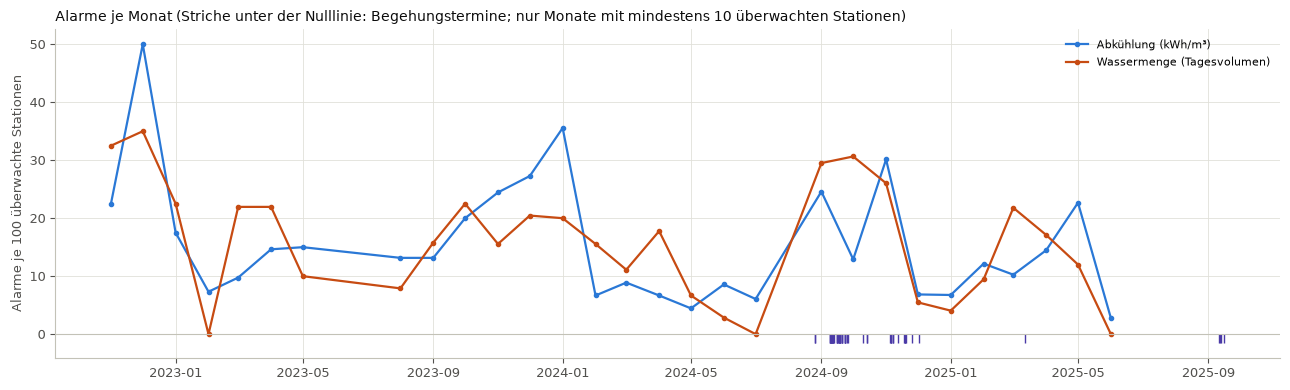

In [12]:
verlaeufe, alarm_zeilen = [], []
for zaehler in stationen:
    v, al = verlauf_station(zaehler)
    verlaeufe.append(v)
    alarm_zeilen.extend(al)
verlauf = pd.concat(verlaeufe, ignore_index=True)
alarme = pd.DataFrame(alarm_zeilen, columns=["zaehler", "kanal", "datum", "richtung", "beginn",
                                             "heiztage_bis_alarm"])

ueberwacht = verlauf[~verlauf["referenz"]]
jahre_je_station = ueberwacht.groupby("zaehler")["datum"].agg(lambda s: (s.max() - s.min()).days / 365.25)
stationsjahre = jahre_je_station.sum()
print(f"{len(stationen)} Stationen ueberwacht, zusammen {stationsjahre:.0f} Stationsjahre")
print(f"{len(alarme)} Alarme in beiden Kanaelen = {len(alarme) / stationsjahre:.1f} je Station und Jahr "
      f"(NB 14: knapp 5)")

zeilen = []
for (kanal, richtung), g in alarme.groupby(["kanal", "richtung"]):
    zeilen.append({"Kanal": KANAELE[kanal], "Richtung": "höher" if richtung > 0 else "niedriger",
                   "Alarme": len(g), "je Stationsjahr": len(g) / stationsjahre,
                   "Stationen mit Alarm": g["zaehler"].nunique(),
                   "Heiztage bis Alarm (Median)": g["heiztage_bis_alarm"].median()})
display(pd.DataFrame(zeilen).round(2))

# Alarme je Monat, bezogen auf die Zahl der Stationen, die in dem Monat ueberwacht wurden
monat = ueberwacht[ueberwacht["kanal"] == "kwh_pro_m3"].assign(monat=lambda x: x["datum"].dt.to_period("M"))
aktiv = monat.groupby("monat")["zaehler"].nunique()
aktiv = aktiv[aktiv >= 10]
alarm_monat = (alarme.assign(monat=alarme["datum"].dt.to_period("M"))
               .groupby(["monat", "kanal"]).size().unstack(fill_value=0)
               .reindex(index=aktiv.index, columns=list(KANAELE), fill_value=0))

fig, ax = plt.subplots(figsize=(13, 4))
x = aktiv.index.to_timestamp()
for kanal, titel in KANAELE.items():
    ax.plot(x, 100 * alarm_monat[kanal] / aktiv, color=FARBE_KANAL[kanal], linewidth=1.6,
            marker="o", markersize=3, label=titel)
ax.vlines(faelle_alle["datum"], 0, -1.5, color=FARBE_BEGANGEN, linewidth=1)
ax.axhline(0, color=ACHSE, linewidth=0.8)
ax.set_ylabel("Alarme je 100 überwachte Stationen", fontsize=9, color=TINTE_LEISE)
ax.set_title("Alarme je Monat (Striche unter der Nulllinie: Begehungstermine; nur Monate mit mindestens "
             "10 überwachten Stationen)", loc="left", fontsize=10, color=TINTE)
ax.legend(frameon=False, fontsize=8)
stil(ax)
fig.tight_layout()
plt.show()

**Was macht die Zelle?**
- rechnet `verlauf_station()` für alle überwachten Stationen; `verlauf` hat eine Zeile je Station, Kanal
  und Heiztag, `alarme` eine Zeile je Alarm
- **Stationsjahre** = Summe der überwachten Zeitspannen. Darauf bezogen ist die Alarmrate unabhängig davon,
  wie lange eine Station Daten hat
- die Grafik teilt die Alarme eines Monats durch die Zahl der in dem Monat überwachten Stationen. So fällt
  ein Monat nicht nur deshalb auf, weil gerade viele Stationen Daten hatten

**Wie man das Ergebnis liest**
- **Alarme je Stationsjahr:** Für die ÜZ zählt, ob das handhabbar ist. Zum Vergleich: der Kennlinienmonitor
  aus NB 14 kam auf knapp 5 je Station und Jahr.
- **Heiztage bis Alarm:** kurz heißt kräftige Sprünge, lang heißt schleichende Veränderungen.
- **Muster über die Monate:**
  - Spitzen im Herbst nach den Begehungsterminen (violette Striche) → passt zur Wirkung der Begehungen,
    Abschnitt 11 prüft das genauer
  - Spitzen **jeden** Herbst oder jedes Frühjahr, auch ohne Begehungen → das Modell übersieht einen
    jahreszeitlichen Effekt. Dann wäre eine zusätzliche Einflussgröße fällig (Ideen am Ende)
  - Spitzen in einem einzelnen Monat bei allen Stationen → netzweites Ereignis (Vorlauftemperatur,
    Messsystem), kein Stationsbefund

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 10 · Sieht das Modell die Begehungen überhaupt?

Bevor man prüft, ob die **Alarme** die Begehungen treffen, eine einfachere Frage: Verschiebt sich das
wetterbereinigte Niveau nach einer Begehung überhaupt, und zwar stärker als bei Stationen ohne Begehung?
Gibt es diese Verschiebung nicht, kann auch kein Alarm sie finden.

**Das Verfahren ist die Differenz-von-Differenzen aus NB 03, aber auf Residuen:**
- **Δ begangen** = Median der Residuen der ersten 30 Heiztage nach der Begehung − Median der letzten 30
  Heiztage davor (jeweils mit 7 Tagen Abstand zum Termin, höchstens ein Jahr weit)
- **Δ Kontrolle** = dasselbe für jede Station, die im verwendeten Zeitraum keine eigene Begehung hatte; davon
  der Median
- **DiD = Δ begangen − Δ Kontrolle**

**Warum das besser ist als in NB 03 und NB 08**
- Die Begehungen lagen im September. „Vorher“ sind damit Heiztage im Frühjahr, „nachher“ Heiztage im Herbst.
  Den Temperaturunterschied zwischen beiden rechnet das Modell heraus, weil es Residuen vergleicht.
- Was sonst noch zwischen Frühjahr und Herbst passiert (Netzfahrweise, Nutzerverhalten nach dem Sommer),
  betrifft auch die Kontrollstationen und fällt durch die zweite Differenz heraus.
- NB 03 hatte die Kontrollgruppe, aber kein Wetter; NB 08 hatte das Wetter, aber keine Kontrollgruppe.

**Einheiten:** Abkühlung in kWh/m³ (positiv = besser), Wassermenge in Prozent (negativ = weniger Wasser).

In [13]:
verlauf_je = {key: g.sort_values("datum") for key, g in verlauf.groupby(["zaehler", "kanal"])}


def begehung_zwischen(zaehler, von, bis):
    """Hatte die Station zwischen von und bis eine Begehung?"""
    return any(von <= t <= bis for t in termine.get(zaehler, []))


def vorher_nachher(zaehler, kanal, datum):
    """Median-Residuum der ersten Heiztage nach minus der letzten vor dem Datum.

    Rueckgabe (Differenz, erster verwendeter Tag, letzter verwendeter Tag) oder None,
    wenn eine Seite zu wenige Tage hat.
    """
    v = verlauf_je[(zaehler, kanal)]
    abstand = pd.Timedelta(days=WIRKUNG_ABSTAND)
    weit = pd.Timedelta(days=WIRKUNG_MAX_TAGE)
    vor = v[(v["datum"] < datum - abstand) & (v["datum"] >= datum - weit)].tail(WIRKUNG_TAGE)
    nach = v[(v["datum"] > datum + abstand) & (v["datum"] <= datum + weit)].head(WIRKUNG_TAGE)
    if len(vor) < MIN_WIRKUNG_TAGE or len(nach) < MIN_WIRKUNG_TAGE:
        return None
    return nach["residuum"].median() - vor["residuum"].median(), vor["datum"].min(), nach["datum"].max()


# Faelle: ueberwachte Stationen, Termin nach dem Ende ihrer Referenz
faelle = faelle_alle[faelle_alle["zaehler"].isin(stationen)].copy()
faelle = faelle[faelle["datum"] >= faelle["zaehler"].map(referenz["ref_ende"])].reset_index(drop=True)
print(f"{len(faelle)} Termine an {faelle['zaehler'].nunique()} ueberwachten Stationen")

kontroll_cache = {}


def kontroll_deltas(kanal, datum):
    """Differenz je Station ohne Begehung im verwendeten Zeitraum (einmal je Datum gerechnet)."""
    if (kanal, datum) not in kontroll_cache:
        werte = {}
        for z in stationen:
            r = vorher_nachher(z, kanal, datum)
            if r is None:
                continue
            delta, von, bis = r
            if begehung_zwischen(z, von - pd.Timedelta(days=WIRKUNG_ABSTAND), bis + pd.Timedelta(days=WIRKUNG_ABSTAND)):
                continue
            werte[z] = delta
        kontroll_cache[(kanal, datum)] = werte
    return kontroll_cache[(kanal, datum)]


zeilen = []
for fall in faelle.itertuples(index=False):
    for kanal in KANAELE:
        eigen = vorher_nachher(fall.zaehler, kanal, fall.datum)
        if eigen is None:
            continue
        kontrolle = [d for z, d in kontroll_deltas(kanal, fall.datum).items() if z != fall.zaehler]
        if len(kontrolle) < MIN_KONTROLLEN:
            continue
        zeilen.append({"zaehler": fall.zaehler, "datum": fall.datum, "kategorie": fall.kategorie,
                       "mechanisch": fall.mechanisch, "kanal": kanal, "delta": eigen[0],
                       "delta_kontrolle": float(np.median(kontrolle)), "n_kontrolle": len(kontrolle)})
wirkung = pd.DataFrame(zeilen, columns=["zaehler", "datum", "kategorie", "mechanisch", "kanal", "delta",
                                        "delta_kontrolle", "n_kontrolle"])
wirkung["did"] = wirkung["delta"] - wirkung["delta_kontrolle"]


def in_einheit(kanal, x):
    return prozent(x) if kanal == "log_volumen" else x


ERWARTET = {"kwh_pro_m3": +1, "log_volumen": -1}   # Richtung einer Verbesserung
zeilen = []
for kanal, g in wirkung.groupby("kanal"):
    p = stats.wilcoxon(g["did"]).pvalue if len(g) >= 6 else np.nan
    zeilen.append({"Kanal": KANAELE[kanal], "Faelle": len(g),
                   "Median Δ begangen": in_einheit(kanal, g["delta"].median()),
                   "Median Δ Kontrolle": in_einheit(kanal, g["delta_kontrolle"].median()),
                   "Median DiD": in_einheit(kanal, g["did"].median()),
                   "Anteil in Richtung Verbesserung": (np.sign(g["did"]) == ERWARTET[kanal]).mean(),
                   "Wilcoxon p (zweiseitig)": p,
                   "Kontrollstationen je Fall (Median)": g["n_kontrolle"].median()})
print("Einheiten: Abkuehlung in kWh/m³, Wassermenge in Prozent")
display(pd.DataFrame(zeilen).round(3))

REIHENFOLGE = {"keine": 0, "geringe": 1, "mittlere": 2, "viele": 3}
for gruppe in ("mechanisch", "kategorie"):
    zeilen = []
    for (kanal, wert), g in wirkung.groupby(["kanal", gruppe]):
        zeilen.append({"Kanal": KANAELE[kanal], gruppe: wert, "Faelle": len(g),
                       "Median DiD": in_einheit(kanal, g["did"].median()),
                       "Anteil in Richtung Verbesserung": (np.sign(g["did"]) == ERWARTET[kanal]).mean()})
    tab = pd.DataFrame(zeilen)
    if gruppe == "kategorie" and len(tab):
        tab["_ordnung"] = tab["kategorie"].map(REIHENFOLGE).fillna(9)
        tab = tab.sort_values(["Kanal", "_ordnung"]).drop(columns="_ordnung")
    print(f"nach {gruppe}:")
    display(tab.round(2))

49 Termine an 47 ueberwachten Stationen
Einheiten: Abkuehlung in kWh/m³, Wassermenge in Prozent


,Kanal,Faelle,Median Δ begangen,Median Δ Kontrolle,Median DiD,Anteil in Richtung Verbesserung,Wilcoxon p (zweiseitig),Kontrollstationen je Fall (Median)
0,Abkühlung (kWh/m³),41,0.793,-0.887,1.299,0.585,0.134,45.0
1,Wassermenge (Tagesvolumen),41,0.531,14.718,-11.257,0.659,0.031,45.0


nach mechanisch:


,Kanal,mechanisch,Faelle,Median DiD,Anteil in Richtung Verbesserung
0,Abkühlung (kWh/m³),False,26,-0.31,0.50
1,Abkühlung (kWh/m³),True,15,2.11,0.73
2,Wassermenge (Tagesvolumen),False,26,-6.98,0.58
3,Wassermenge (Tagesvolumen),True,15,-13.81,0.80


nach kategorie:


,Kanal,kategorie,Faelle,Median DiD,Anteil in Richtung Verbesserung
1,Abkühlung (kWh/m³),keine,2,-2.44,0.00
0,Abkühlung (kWh/m³),geringe,4,-0.06,0.50
2,Abkühlung (kWh/m³),mittlere,25,1.34,0.64
3,Abkühlung (kWh/m³),viele,10,1.58,0.60
5,Wassermenge (Tagesvolumen),keine,2,11.93,0.50
4,Wassermenge (Tagesvolumen),geringe,4,6.59,0.25
6,Wassermenge (Tagesvolumen),mittlere,25,-11.34,0.68
7,Wassermenge (Tagesvolumen),viele,10,-9.58,0.80


**Was macht die Zelle?**
- `vorher_nachher()` rechnet für eine Station und ein Datum die Verschiebung des Medianresiduums
- `faelle` sind alle Begehungstermine an überwachten Stationen nach dem Ende ihrer Referenz
- für jeden Fall wird dieselbe Rechnung an allen Kontrollstationen gemacht (je Datum nur einmal, deshalb der
  Zwischenspeicher `kontroll_cache`)
- die erste Tabelle fasst je Kanal zusammen, die zweite teilt nach mechanischem Befund und nach der Kategorie
  aus der Begehungstabelle

**Wie man das Ergebnis liest**
- **Median DiD** ist die typische wetterbereinigte Wirkung einer Begehung, über das hinaus, was ohnehin
  passiert ist. Zum Vergleich: NB 08 fand ohne Kontrollgruppe +2,7 bis +2,9 kWh/m³, NB 12 auf Tagesebene
  +1,1 kWh/m³ ohne Kontrollgruppe.
- **Anteil in Richtung Verbesserung:** 0,5 wäre Zufall. Darüber heißt: bei den meisten Stationen wird es
  besser.
- **Wilcoxon p:** testet, ob die DiD-Werte im Median von null verschieden sind. Fälle derselben Station sind
  nicht unabhängig, der p-Wert ist also eher zu optimistisch.
- **Mechanisch gegen nicht mechanisch:** Wenn die mechanischen Eingriffe deutlich größere DiD haben, ist das
  dieselbe Aussage wie in NB 15, diesmal mit Wetterbereinigung und Kontrollgruppe.

**Was „kein Effekt“ hier bedeuten würde**
- Wenn das Niveau nach den Begehungen nicht stärker wandert als bei den Kontrollstationen, kann auch der Alarm
  in Abschnitt 11 die Begehungen nicht finden. Dann liegt das nicht am Alarm, sondern daran, dass die meisten
  Begehungen die Tagesbilanz nicht messbar ändern.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

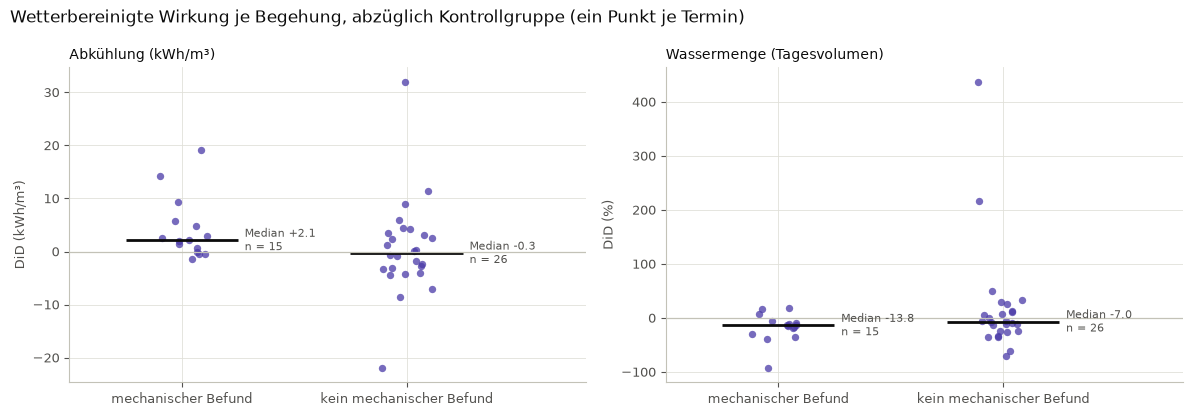

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rng = np.random.default_rng(SEED)
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    g = wirkung[wirkung["kanal"] == kanal]
    for pos, (wert, name) in enumerate([(True, "mechanischer Befund"), (False, "kein mechanischer Befund")]):
        y = in_einheit(kanal, g.loc[g["mechanisch"] == wert, "did"].to_numpy())
        x = pos + rng.uniform(-0.12, 0.12, len(y))
        ax.scatter(x, y, s=28, color=FARBE_BEGANGEN, alpha=0.75, linewidths=0)
        if len(y):
            ax.hlines(np.median(y), pos - 0.25, pos + 0.25, color=TINTE, linewidth=2)
            ax.text(pos + 0.28, np.median(y), f"Median {np.median(y):+.1f}\nn = {len(y)}",
                    fontsize=8, color=TINTE_LEISE, va="center")
    ax.axhline(0, color=ACHSE, linewidth=0.9)
    ax.set_xticks([0, 1], ["mechanischer Befund", "kein mechanischer Befund"])
    ax.set_xlim(-0.5, 1.8)
    einheit = "%" if kanal == "log_volumen" else "kWh/m³"
    ax.set_ylabel(f"DiD ({einheit})", fontsize=9, color=TINTE_LEISE)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    stil(ax)
fig.suptitle("Wetterbereinigte Wirkung je Begehung, abzüglich Kontrollgruppe (ein Punkt je Termin)",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- Jeder Punkt ist ein Begehungstermin, der Querstrich der Median der Gruppe.
- Abkühlung: Punkte **über** null heißt, die Station kühlt nach der Begehung besser aus als die
  Kontrollstationen im selben Zeitraum.
- Wassermenge: Punkte **unter** null heißt, sie zieht weniger Wasser.
- Einzelne weit entfernte Punkte sind die interessanten Fälle für die ÜZ (zum Beispiel der Ventilfall).

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 11 · Treffen die Alarme die Begehungen?

**Die Prüfung**
- **Treffer:** mindestens ein Alarm im Fenster von 7 Tagen vor bis 60 Tage nach der Begehung. Gezählt wird je
  Kanal und für „einer der beiden Kanäle“.
- **Erwartung ohne Begehung:** der Anteil der Kontrollstationen mit Alarm **im selben Fenster**. Kontrollstation
  ist jede überwachte Station, die im Fenster mindestens 5 Heiztage hat und in den 60 Tagen davor und im
  Fenster selbst keine eigene Begehung hatte.
- **Test:** Binomialtest, einseitig. Liegen die Treffer über dem, was die Kontrollstationen im selben Zeitraum
  liefern?

**Warum eine Kontrollgruppe statt einer Zufallsbasis wie in NB 14?**
- Die Begehungen liegen fast alle im September, also kurz vor der Heizperiode.
- Wenn das Modell im Herbst überall häufiger alarmiert, zum Beispiel weil die Heizungen nach dem Sommer
  anders anlaufen, würde eine Zufallsbasis über das ganze Jahr die Treffer schönrechnen.
- Die Kontrollgruppe hat dasselbe Datum und damit denselben Herbsteffekt.

In [15]:
alarme_je = {key: g["datum"] for key, g in alarme.groupby(["zaehler", "kanal"])}
tage_je = {z: g["datum"] for z, g in ueberwacht[ueberwacht["kanal"] == "kwh_pro_m3"].groupby("zaehler")}
PRUEFUNGEN = {"Abkühlung": ["kwh_pro_m3"], "Wassermenge": ["log_volumen"],
              "einer der beiden": list(KANAELE)}


def alarm_im_fenster(zaehler, kanaele, von, bis):
    for kanal in kanaele:
        s = alarme_je.get((zaehler, kanal))
        if s is not None and ((s >= von) & (s <= bis)).any():
            return True
    return False


def beobachtbar(zaehler, von, bis):
    """Hat die Station im Fenster genug ueberwachte Heiztage, um ueberhaupt alarmieren zu koennen?"""
    s = tage_je.get(zaehler)
    return s is not None and int(((s >= von) & (s <= bis)).sum()) >= MIN_TAGE_IM_FENSTER


zeilen = []
for fall in faelle.itertuples(index=False):
    von = fall.datum - pd.Timedelta(days=FENSTER_VOR)
    bis = fall.datum + pd.Timedelta(days=FENSTER_NACH)
    if not beobachtbar(fall.zaehler, von, bis):
        continue
    kontrollen = [z for z in stationen
                  if z != fall.zaehler and beobachtbar(z, von, bis)
                  and not begehung_zwischen(z, von - pd.Timedelta(days=KONTROLL_VORLAUF), bis)]
    if len(kontrollen) < MIN_KONTROLLEN:
        continue
    for name, kanaele in PRUEFUNGEN.items():
        zeilen.append({"zaehler": fall.zaehler, "datum": fall.datum, "mechanisch": fall.mechanisch,
                       "kategorie": fall.kategorie, "pruefung": name,
                       "treffer": alarm_im_fenster(fall.zaehler, kanaele, von, bis),
                       "kontrollquote": np.mean([alarm_im_fenster(z, kanaele, von, bis) for z in kontrollen]),
                       "n_kontrolle": len(kontrollen)})
treffer = pd.DataFrame(zeilen, columns=["zaehler", "datum", "mechanisch", "kategorie", "pruefung",
                                        "treffer", "kontrollquote", "n_kontrolle"])


def bilanz(t, gruppen):
    """Treffer gegen Kontrollquote je Gruppe, mit einseitigem Binomialtest."""
    zeilen = []
    for schluessel, g in t.groupby(gruppen, sort=False):
        n, k = len(g), int(g["treffer"].sum())
        p0 = float(g["kontrollquote"].mean())
        p = stats.binomtest(k, n, p0, alternative="greater").pvalue if 0 < p0 < 1 else np.nan
        schluessel = schluessel if isinstance(schluessel, tuple) else (schluessel,)
        zeilen.append({**dict(zip(gruppen, schluessel)), "Faelle": n, "Treffer": k, "Quote": k / n,
                       "Kontrollquote": p0, "Hebel": (k / n) / p0 if p0 > 0 else np.nan,
                       "p (einseitig)": p})
    return pd.DataFrame(zeilen)


gesamt = bilanz(treffer, ["pruefung"])
nach_art = bilanz(treffer, ["pruefung", "mechanisch"])
display(gesamt.round(3))
display(nach_art.round(3))

# Verzoegerung und Richtung des ersten Alarms nach der Begehung
erste = []
for fall in faelle.itertuples(index=False):
    for kanal in KANAELE:
        s = alarme[(alarme["zaehler"] == fall.zaehler) & (alarme["kanal"] == kanal)
                   & alarme["datum"].between(fall.datum - pd.Timedelta(days=FENSTER_VOR),
                                             fall.datum + pd.Timedelta(days=FENSTER_NACH))]
        if len(s):
            a = s.sort_values("datum").iloc[0]
            erste.append({"kanal": kanal, "tage": (a["datum"] - fall.datum).days,
                          "verbesserung": a["richtung"] == ERWARTET[kanal]})
erste = pd.DataFrame(erste, columns=["kanal", "tage", "verbesserung"])
for kanal, g in erste.groupby("kanal"):
    print(f"{KANAELE[kanal]}: erster Alarm im Median {g['tage'].median():.0f} Tage nach der Begehung, "
          f"{g['verbesserung'].mean():.0%} davon in Richtung Verbesserung (n = {len(g)})")

,pruefung,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,41,21,0.512,0.289,1.771,0.002
1,Wassermenge,41,22,0.537,0.383,1.400,0.033
2,einer der beiden,41,29,0.707,0.530,1.336,0.016


,pruefung,mechanisch,Faelle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,Abkühlung,True,14,5,0.357,0.286,1.249,0.370
1,Wassermenge,True,14,9,0.643,0.408,1.575,0.066
2,einer der beiden,True,14,10,0.714,0.541,1.321,0.151
3,Abkühlung,False,27,16,0.593,0.291,2.037,0.001
4,Wassermenge,False,27,13,0.481,0.371,1.299,0.160
5,einer der beiden,False,27,19,0.704,0.524,1.344,0.045


Abkühlung (kWh/m³): erster Alarm im Median 19 Tage nach der Begehung, 43% davon in Richtung Verbesserung (n = 21)
Wassermenge (Tagesvolumen): erster Alarm im Median 10 Tage nach der Begehung, 82% davon in Richtung Verbesserung (n = 22)


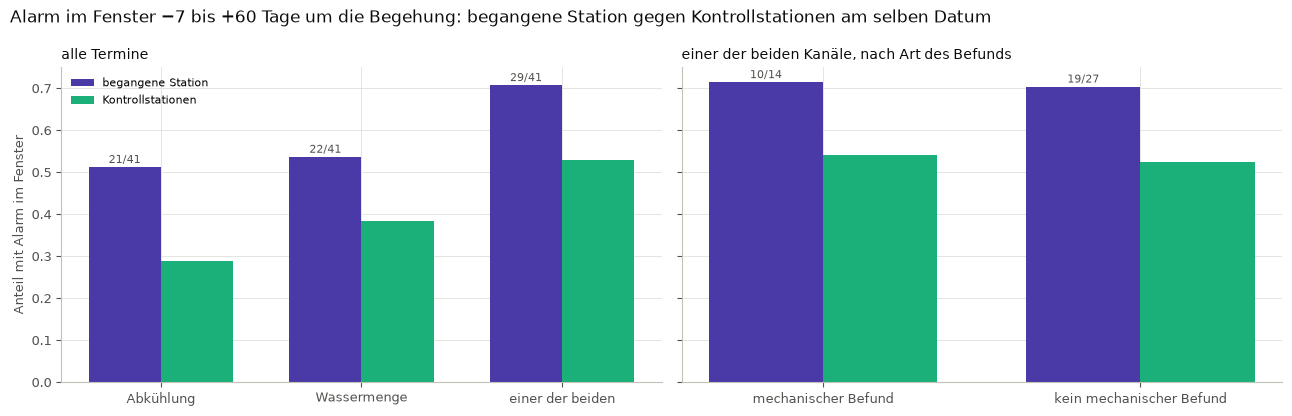

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
breite = 0.36
for ax, (daten, titel) in zip(axes, [(gesamt, "alle Termine"),
                                     (nach_art[nach_art["pruefung"] == "einer der beiden"],
                                      "einer der beiden Kanäle, nach Art des Befunds")]):
    if "mechanisch" in daten.columns:
        namen = ["mechanischer Befund" if m else "kein mechanischer Befund" for m in daten["mechanisch"]]
    else:
        namen = list(daten["pruefung"])
    x = np.arange(len(daten))
    ax.bar(x - breite / 2, daten["Quote"], breite, color=FARBE_BEGANGEN, label="begangene Station")
    ax.bar(x + breite / 2, daten["Kontrollquote"], breite, color=FARBE_KONTROLLE, label="Kontrollstationen")
    for xi, (k, n) in enumerate(zip(daten["Treffer"], daten["Faelle"])):
        ax.text(xi - breite / 2, daten["Quote"].iloc[xi] + 0.01, f"{k}/{n}", ha="center", fontsize=8,
                color=TINTE_LEISE)
    ax.set_xticks(x, namen, fontsize=9)
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    stil(ax)
axes[0].set_ylabel("Anteil mit Alarm im Fenster", fontsize=9, color=TINTE_LEISE)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Alarm im Fenster −{FENSTER_VOR} bis +{FENSTER_NACH} Tage um die Begehung: "
             "begangene Station gegen Kontrollstationen am selben Datum", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Was machen die beiden Zellen?**
- prüfen für jeden Termin, ob die begangene Station im Fenster einen Alarm hat, und welcher Anteil der
  Kontrollstationen im selben Fenster einen Alarm hat
- `gesamt`: je Prüfung (Abkühlung, Wassermenge, einer der beiden); `nach_art`: zusätzlich nach mechanischem
  Befund getrennt
- darunter: wie viele Tage nach der Begehung der erste Alarm kam und ob er in Richtung Verbesserung zeigte
- die Grafik stellt Quote (violett) und Kontrollquote (türkis) nebeneinander, über den Balken Treffer/Fälle

**Wie man das Ergebnis liest**
- **Hebel** = Quote / Kontrollquote. 1 heißt: nach einer Begehung klingelt es genauso oft wie ohne. NB 14 kam
  auf rund 1,3, NB 15 bei mechanischen Befunden auf rund 1,8 (0,526 gegen 0,287).
- **p (einseitig):** Wahrscheinlichkeit, mindestens so viele Treffer zu bekommen, wenn die Begehung keinen
  Einfluss hätte. Unter 0,05 gilt üblicherweise als nicht mehr zufällig. Die Fälle sind nicht ganz unabhängig
  (gleiche Stationen, gleiche Daten), der p-Wert ist also eher zu optimistisch.
- **Richtung:** Ein Alarm „Abkühlung höher“ oder „Wassermenge niedriger“ nach einer Begehung passt zu einer
  Verbesserung. Alarme in die andere Richtung nach einer Begehung wären selbst interessant (Fall 72167783 aus
  NB 03: Rücklauf nach der Begehung von 18,6 auf 71,0 °C).
- Wichtig: die Ergebnisse aus Abschnitt 10 und 11 zusammen lesen. Abschnitt 10 sagt, ob es ein Signal gibt,
  Abschnitt 11, ob der Alarm es rechtzeitig findet.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 12 · Station gegen Flotte

**Die Lücke des Modells:** Es vergleicht jede Station mit sich selbst. Eine Station, die schon im ersten Jahr
schlecht lief, gilt dadurch als „normal“ und alarmiert nie.

**Die Ergänzung:** Die Abkühlungs-Kennlinie jeder Station liefert ihre Abkühlung bei einer **Normtemperatur von 5 °C**. Dadurch
sind die Stationen vergleichbar, auch wenn ihre Daten aus verschiedenen Wintern stammen. Das ist dieselbe Idee
wie der Bezugspunkt in NB 08.

- **Normkennzahl Referenz** = Wert der Kennlinie bei 5 °C: Zustand im ersten Jahr
- **Normkennzahl aktuell** = Normkennzahl Referenz + Median der Residuen der letzten 60 Heiztage: Zustand am
  Ende der Daten
- **Abstand zur Flotte** = (Flottenmedian − Station) / 1,15, in Kelvin Spreizung: so viel Spreizung fehlt
  gegenüber einer typischen Station

Nur die Abkühlung, weil kWh/m³ nicht von der Hausgröße abhängt. Das Tagesvolumen tut es, ein Vergleich
zwischen Stationen würde nur nach Größe sortieren.

Flottenmedian aktuell: 26.1 kWh/m³ bei 5 °C (= 22.7 K Spreizung)


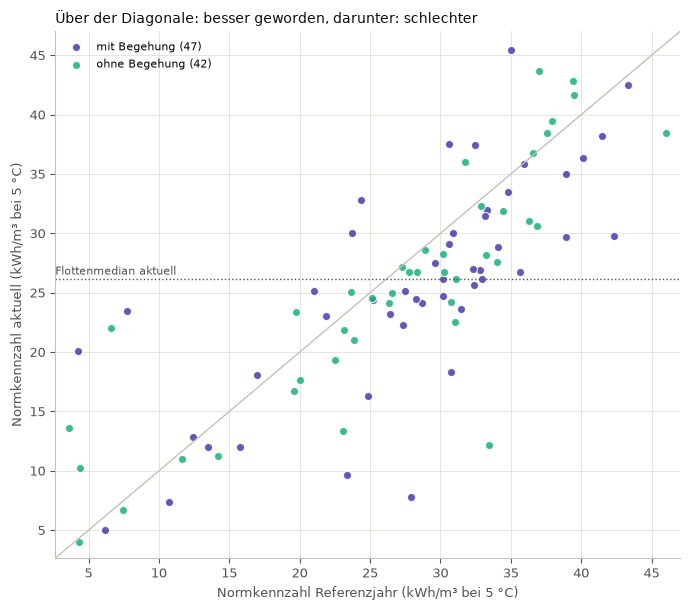

Zehn Stationen mit der niedrigsten Abkuehlung aktuell (groesstes Optimierungspotenzial):


,zaehler,norm_referenz,norm_aktuell,abstand_k,veraenderung,stand,begangen,alarme
88,721354800,4.32,4.01,19.23,-0.31,2024-05-10,False,8
71,80912182,6.21,5.04,18.33,-1.16,2025-06-09,True,3
50,72167793,7.43,6.73,16.86,-0.70,2025-06-09,False,2
34,72135442,10.75,7.37,16.31,-3.38,2025-06-09,True,8
26,68956372,27.91,7.75,15.97,-20.15,2024-05-18,True,4
64,80912173,23.39,9.66,14.31,-13.73,2025-06-09,True,3
40,72135480,4.39,10.27,13.79,5.88,2025-06-09,False,4
36,72135453,11.62,11.03,13.13,-0.60,2025-06-09,False,10
87,81062289,14.19,11.21,12.97,-2.97,2025-06-09,False,3
17,68956356,13.50,11.97,12.31,-1.53,2025-06-09,True,6


In [17]:
zeilen = []
for zaehler in stationen:
    norm_referenz = float(erwartung(zaehler, "kwh_pro_m3", T_NORM))
    letzte = verlauf_je[(zaehler, "kwh_pro_m3")].tail(AKTUELL_TAGE)
    zeilen.append({"zaehler": zaehler, "norm_referenz": norm_referenz,
                   "norm_aktuell": norm_referenz + letzte["residuum"].median(),
                   "stand": letzte["datum"].max(),
                   "alarme": int((alarme["zaehler"] == zaehler).sum()),
                   "begangen": zaehler in termine})
flotte = pd.DataFrame(zeilen)
median_flotte = flotte["norm_aktuell"].median()
flotte["abstand_k"] = (median_flotte - flotte["norm_aktuell"]) / RHO_C
flotte["veraenderung"] = flotte["norm_aktuell"] - flotte["norm_referenz"]
print(f"Flottenmedian aktuell: {median_flotte:.1f} kWh/m³ bei {T_NORM:g} °C "
      f"(= {median_flotte / RHO_C:.1f} K Spreizung)")

fig, ax = plt.subplots(figsize=(7, 6.2))
for wert, farbe, name in [(True, FARBE_BEGANGEN, "mit Begehung"), (False, FARBE_KONTROLLE, "ohne Begehung")]:
    g = flotte[flotte["begangen"] == wert]
    ax.scatter(g["norm_referenz"], g["norm_aktuell"], s=34, color=farbe, alpha=0.85, linewidths=0.8,
               edgecolors="white", label=f"{name} ({len(g)})")
grenzen = [flotte[["norm_referenz", "norm_aktuell"]].min().min() - 1,
           flotte[["norm_referenz", "norm_aktuell"]].max().max() + 1]
ax.plot(grenzen, grenzen, color=ACHSE, linewidth=1)
ax.axhline(median_flotte, color=TINTE_LEISE, linestyle=":", linewidth=1)
ax.text(grenzen[0], median_flotte + 0.4, "Flottenmedian aktuell", fontsize=8, color=TINTE_LEISE)
ax.set_xlim(grenzen)
ax.set_ylim(grenzen)
ax.set_xlabel(f"Normkennzahl Referenzjahr (kWh/m³ bei {T_NORM:g} °C)", fontsize=9, color=TINTE_LEISE)
ax.set_ylabel(f"Normkennzahl aktuell (kWh/m³ bei {T_NORM:g} °C)", fontsize=9, color=TINTE_LEISE)
ax.set_title("Über der Diagonale: besser geworden, darunter: schlechter", loc="left", fontsize=10, color=TINTE)
ax.legend(frameon=False, fontsize=8, loc="upper left")
stil(ax)
fig.tight_layout()
plt.show()

print("Zehn Stationen mit der niedrigsten Abkuehlung aktuell (groesstes Optimierungspotenzial):")
zahlen = ["norm_referenz", "norm_aktuell", "abstand_k", "veraenderung"]
display(flotte.nsmallest(10, "norm_aktuell")[["zaehler", *zahlen, "stand", "begangen", "alarme"]]
        .round({sp: 2 for sp in zahlen}))

In [18]:
# Gegenprobe mit NB 06: Anteil der Heiztage im schlechtesten Tagestyp (der Typ mit der
# niedrigsten mittleren Abkuehlung, bei K = 4 der Dauerdurchfluss-Typ D)
heiz = tage[tage["heiztag"] & tage["cluster"].notna()]
if len(heiz):
    schlechtester = heiz.groupby("cluster")["kwh_pro_m3"].median().idxmin()
    anteil = heiz.groupby("zaehler")["cluster"].apply(lambda c: (c == schlechtester).mean())
    vergleich = flotte.set_index("zaehler").join(anteil.rename("anteil_schlechtester_typ"), how="inner")
    rho, p = stats.spearmanr(vergleich["norm_referenz"], vergleich["anteil_schlechtester_typ"])
    print(f"schlechtester Tagestyp in NB 06: {schlechtester}")
    print(f"Spearman Normkennzahl Referenz gegen Anteil dieses Typs: rho = {rho:+.2f}, p = {p:.2g}, "
          f"n = {len(vergleich)}")
else:
    print("hast_tage.csv enthaelt keine Clusterspalte - Gegenprobe uebersprungen")

schlechtester Tagestyp in NB 06: D
Spearman Normkennzahl Referenz gegen Anteil dieses Typs: rho = -0.58, p = 9.2e-09, n = 83


**Was machen die beiden Zellen?**
- rechnen je Station die Normkennzahl im Referenzjahr und aktuell, den Abstand zum Flottenmedian in Kelvin und
  die Veränderung seit der Referenz
- das Bild stellt Referenz (x) gegen aktuell (y): auf der Diagonale hat sich nichts geändert
- die Tabelle listet die zehn Stationen mit der niedrigsten aktuellen Abkühlung, also dem größten Potenzial
- die Gegenprobe vergleicht mit NB 06: Stationen mit vielen Tagen im schlechtesten Tagestyp sollten eine
  niedrige Normkennzahl haben

**Wie man das Ergebnis liest**
- **Unten links** im Bild: dauerhaft schlechte Stationen. Genau die, die der Alarm nicht finden kann, weil sie
  sich nicht verändern. Für die ÜZ die wichtigste Liste.
- **Deutlich über der Diagonale:** Stationen, die besser geworden sind. Violett (mit Begehung) passt zu einer
  Wirkung der Begehung.
- **Deutlich unter der Diagonale:** Stationen, die schlechter geworden sind. Kandidaten für eine Begehung.
- `abstand_k`: positiv heißt, die Station hat so viel Kelvin weniger Spreizung als der Flottenmedian.
- `stand`: Datum des letzten Heiztags, auf dem „aktuell“ beruht. Bei Stationen mit früh endenden Daten ist
  „aktuell“ entsprechend älter.
- **Gegenprobe:** ein deutlich negatives rho heißt, Normkennzahl und NB-06-Tagestypen messen dasselbe. Liegt es
  nahe null, stimmt eines von beiden nicht.

**Ergebnis** *(nach dem ersten Lauf ausfüllen)*
- …

## 13 · Ergebnis speichern

In [19]:
AUSGABE.mkdir(parents=True, exist_ok=True)

breit = parameter.pivot(index="zaehler", columns="kanal",
                        values=["form", "b", "klassen", "kalt_minus_mild", "s", "autokorrelation", "faktor"])
breit.columns = [f"{wert}_{kanal}" for wert, kanal in breit.columns]
stationstabelle = (referenz.join(breit)
                   .join(flotte.set_index("zaehler")[["norm_referenz", "norm_aktuell", "abstand_k",
                                                      "veraenderung", "stand", "alarme"]]))
stationstabelle.to_csv(AUSGABE / "normalmodell_stationen.csv")
verlauf.to_csv(AUSGABE / "normalmodell_tage.csv", index=False)
alarme.to_csv(AUSGABE / "normalmodell_alarme.csv", index=False)
wirkung.to_csv(AUSGABE / "normalmodell_wirkung.csv", index=False)
treffer.to_csv(AUSGABE / "normalmodell_treffer.csv", index=False)

parameter_lauf = {
    "T_HEIZGRENZE": T_HEIZGRENZE, "IGNORIERTE_MARKIERUNGEN": sorted(IGNORIERTE_MARKIERUNGEN),
    "KANAELE": list(KANAELE), "FORM_JE_KANAL": FORM_JE_KANAL, "KLASSENBREITE_K": KLASSENBREITE_K,
    "MIN_TAGE_JE_KLASSE": MIN_TAGE_JE_KLASSE,
    "AUTOKORRELATION_BERUECKSICHTIGEN": AUTOKORRELATION_BERUECKSICHTIGEN, "PHI_MAX": PHI_MAX,
    "REF_KALENDERTAGE": REF_KALENDERTAGE, "ABSTAND_BEGEHUNG": ABSTAND_BEGEHUNG,
    "MIN_REF_TAGE": MIN_REF_TAGE, "MIN_REF_SPANNE_K": MIN_REF_SPANNE_K, "PRUEF_TAGE": PRUEF_TAGE,
    "CUSUM_K": CUSUM_K, "CUSUM_H": CUSUM_H, "CUSUM_MAX": CUSUM_MAX,
    "FENSTER_VOR": FENSTER_VOR, "FENSTER_NACH": FENSTER_NACH, "MIN_TAGE_IM_FENSTER": MIN_TAGE_IM_FENSTER,
    "KONTROLL_VORLAUF": KONTROLL_VORLAUF, "MIN_KONTROLLEN": MIN_KONTROLLEN, "WIRKUNG_TAGE": WIRKUNG_TAGE,
    "MIN_WIRKUNG_TAGE": MIN_WIRKUNG_TAGE, "WIRKUNG_ABSTAND": WIRKUNG_ABSTAND,
    "WIRKUNG_MAX_TAGE": WIRKUNG_MAX_TAGE, "T_NORM": T_NORM, "AKTUELL_TAGE": AKTUELL_TAGE,
}
meta = {
    "erzeugt": pd.Timestamp.now().isoformat(timespec="seconds"),
    "quelle": str(TAGE_PATH.relative_to(ROOT)),
    "parameter": parameter_lauf,
    "stationen_ueberwacht": len(stationen),
    "status": referenz["status"].value_counts().to_dict(),
    "stationsjahre": round(float(stationsjahre), 1),
    "alarme": int(len(alarme)),
    "alarme_je_stationsjahr": round(len(alarme) / stationsjahre, 2),
    "skill_median": guete.groupby("kanal")["skill"].median().round(3).to_dict(),
    "wirkung_median_did": wirkung.groupby("kanal")["did"].median().round(4).to_dict(),
    "treffer": gesamt.round(4).to_dict(orient="records"),
}
(AUSGABE / "normalmodell.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str),
                                           encoding="utf-8")
for name in ["normalmodell_stationen.csv", "normalmodell_tage.csv", "normalmodell_alarme.csv",
             "normalmodell_wirkung.csv", "normalmodell_treffer.csv", "normalmodell.json"]:
    print(f"-> {name}")

-> normalmodell_stationen.csv
-> normalmodell_tage.csv
-> normalmodell_alarme.csv
-> normalmodell_wirkung.csv
-> normalmodell_treffer.csv
-> normalmodell.json


**Was wird gespeichert?** (alles in `data/processed/`, gitignored)

| Datei | Inhalt |
|---|---|
| `normalmodell_stationen.csv` | je Station: Referenzzeitraum, Status, Form, Steigung, Streuung und Korrekturfaktor je Kanal, Normkennzahlen, Zahl der Alarme |
| `normalmodell_tage.csv` | je Station, Kanal und Heiztag: gemessen, erwartet, Residuum, z-Wert, CUSUM-Konten |
| `normalmodell_alarme.csv` | je Alarm: Station, Kanal, Datum, Richtung, geschätzter Beginn |
| `normalmodell_wirkung.csv` | je Begehungstermin und Kanal: Δ begangen, Δ Kontrolle, DiD |
| `normalmodell_treffer.csv` | je Begehungstermin und Prüfung: Treffer ja/nein, Kontrollquote |
| `normalmodell.json` | alle Parameter dieses Laufs und die wichtigsten Kennzahlen |

**Datenschutz:** Die CSVs enthalten Zählernummern. `data/processed/` ist gitignored und bleibt es. Vor einem
Commit die Ausgaben der Zellen mit Stationslisten (Abschnitt 8, 12) prüfen.

## 14 · Einordnung und Verbesserungsideen

### Fragen an das Ergebnis *(nach dem ersten Lauf ausfüllen)*

1. **Passt die Kennlinie?** Bild in Abschnitt 2 gerade oder krumm, passt `FORM_JE_KANAL` dazu? Skill in Abschnitt 6 deutlich über null?
2. **Wird der Ventilfall gefunden, und wann?** (Abschnitt 8)
3. **Wie viele Alarme je Station und Jahr?** Häufen sie sich jeden Herbst? (Abschnitt 9)
4. **Gibt es überhaupt ein Signal?** Ist der wetterbereinigte Effekt der Begehungen größer als bei der
   Kontrollgruppe? Bei mechanischen Befunden stärker? (Abschnitt 10)
5. **Findet der Alarm das Signal?** Hebel über 1, p unter 0,05? Besser als NB 14 (1,3)? (Abschnitt 11)
6. **Passt die Normkennzahl zu NB 06?** Und welche Stationen stehen unten links? (Abschnitt 12)

### Bekannte Grenzen

- **Nur Heiztage.** Fehler, die nur im Sommer auffallen (Dauerzirkulation), sieht dieses Modell nicht.
- **Referenz = erstes Jahr.** Stationen mit zu kurzer Referenz fehlen; eine Station, die schon am Anfang
  schlecht lief, gilt als normal (dafür Abschnitt 12).
- **Zählertausch** ist nicht zusammengeführt (wie in NB 06): eine HAST mit Tausch erscheint als zwei Zähler.
- **Datenende:** Zählerstände gibt es bis Juli 2025, das Wetter bis Ende 2025. Nach den Begehungen vom
  September 2024 bleibt ein voller Winter.
- **Tage sind nicht unabhängig.** Die Autokorrelation erhöht die Fehlalarmrate, und die p-Werte in Abschnitt 10
  und 11 sind eher zu optimistisch.
- **Schwellen gesetzt, nicht hergeleitet.** k, h und die Fenster sind Lehrbuch- bzw. Startwerte.
- **Streuung s aus der Referenz.** Auf den Referenztagen passt die Kennlinie besser als auf neuen Tagen. Die
  z-Werte nach der Referenz sind dadurch etwas größer, als sie bei einem perfekten Modell wären.

### Verbesserungsideen

| Idee | Was sie bringt | Wo ändern |
|---|---|---|
| Mittel der Außentemperatur über 2–3 Tage statt nur des Tages | Gebäude reagieren träge; ein Wetterumschwung erzeugt sonst einen Tag mit großem Residuum | `lerne_kennlinie`, `kennlinienwert`: zweite Einflussgröße |
| Wochentag als Einflussgröße | Schulen, Gewerbe, Wochenendhäuser verhalten sich am Wochenende anders | wie oben |
| Knickgerade als dritte Form | glatter als die Klassenkennlinie, aber auch für krumme Zusammenhänge | `lerne_kennlinie`, `kennlinienwert` |
| Vorlauftemperatur als Einflussgröße | netzweite Änderungen (Vorlauf hochgefahren) werden erklärt statt alarmiert; `vorlauf_c` steht schon in `hast_tage.csv` | `lerne_kennlinie` mit zwei Größen |
| Sommerkanal: Nachtfluss je kW an Tagen über 15 °C | findet Dauerdurchfluss im Sommer (NB 06 Sommer-Typ C) | eigener Kanal in `KANAELE`, eigene Tagesauswahl |
| Referenz nach einem bestätigten Wechsel neu lernen | nach einer Reparatur wieder empfindlich für neue Fehler | `verlauf_station` |
| h über die Fehlalarmrate der Kontrollstationen festlegen | Schwelle hergeleitet statt gesetzt, z. B. „höchstens 1 Fehlalarm je Station und Jahr“ | Abschnitt 9 |
| Zählertausch zusammenführen | längere Reihen, mehr Stationen mit Referenz | NB 00 / NB 06 |
| neue Begehungen als Prüfdaten | sauberer Test mit vorab festgelegten Parametern | Abschnitt 11 |

### Wie das Ergebnis einzuordnen ist *(nach dem ersten Lauf ausfüllen)*

- **Belastbar:** …
- **Schwach:** …
- **Offen / fürs Team:** …